# Which weights make the model pick one algorithm? — BASE-W (iteration 10), CPU demo

**The run's question:** can we make an LLM write a *different*, less default solution? Earlier iterations found that when
**Qwen3-8B** writes a program it commits to an algorithm at one **fork token**. For connected components (unit **T10**) the
prefilled assistant opening is ```` ```python\ndef solve(n, edges):\n    def````. The next token is either ` find`
(union-find, the instruct default, class **D**) or ` dfs` / ` bfs` (the alternatives, class **A**). Post-training sharpened
that choice relative to **Qwen3-8B-Base**.

This artifact asks **which weights** hold that default:

| arm | what is swapped to the base model | where it runs |
|---|---|---|
| **W1** readout rows | the fork-class **unembedding rows** (and/or the final-norm gain), read on the *instruct* residual | **CPU, re-run here** |
| **W2** late MLPs | layers 26-35 swapped in place, against Frobenius-matched early swaps | GPU (reported at the end) |
| **W3** Gemma-3-4b | the W1 row test at Gemma's grid fork | GPU (reported at the end) |

**Metric.** At the fork, the margin is $m=\mathrm{lse}(z[D])-\mathrm{lse}(z[A])$, i.e. the log-odds of the default class.
An arm's **share** is the fraction of the instruct-minus-base gap it closes:
$\text{share}=\sum_p (m_{I,p}-m_{arm,p})\,/\,\sum_p (m_{I,p}-m_{B,p})$, a ratio of sums over prompts with a 95% prompt bootstrap.
Share 0 means the edit does nothing; share 1 means it recovers the base model's margin.

**What this notebook runs (CPU, exact, seconds).** The class margin depends only on the fork-class rows $S=D\cup A$ and on
the final-normed residual. So the whole W1 teacher-forced analysis is exact arithmetic on cached fork states.
`mini_demo_data.json` ships, for the **20 T10 prompts**:
* both models' bf16 fork states;
* the bf16 unembedding rows of the 3 fork tokens and of the 147 tokens the DELTA_SWAP null draws;
* the final-norm gains and the residual-PCA basis;
* the 630 labelled T10 generations.

From these the notebook re-runs, with the original code:
1. the stage-0 checks (final-norm recompute, CPU readout decomposition);
2. the three committed null families (50 draws each, regenerated from the committed seeds);
3. every W1 readout arm with bootstrap CIs, the committed verdict rule and the specificity qualifier;
4. the 2×2 readout × residual factorial and the per-token logit changes;
5. the delta geometry (why residual-subspace nulls out-lever the real deltas);
6. **activation-space plots**: the fork states on the readout plane, and a PCA of the block-35 outputs;
7. the generation statistics (correct-DFS counts per arm, exact McNemar tests on common-random-number pairs).

**What it cannot run.** Model captures, free generation, the W2 weight swaps and W3 (Gemma) all need the 8B models on a
GPU. Their reported numbers are printed in the last code cell.


In [1]:
import subprocess, sys
def _pip(*a): subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *a])

# loguru -- NOT on Colab, always install
_pip('loguru==0.7.3')

# numpy, scipy, matplotlib, torch -- pre-installed on Colab, install locally only (torch as the CPU wheel)
if 'google.colab' not in sys.modules:
    _pip('numpy==2.0.2', 'scipy==1.16.3', 'matplotlib==3.10.0')
    _pip('torch==2.9.0', '--index-url', 'https://download.pytorch.org/whl/cpu')


In [2]:
# Imports of the original modules (cfg10.py, w1_tf.py, analysis10.py, figures10.py, w1_gen.py, stats9.py)
import hashlib
import itertools
import json
import math
import os
import sys
import time
from datetime import datetime, timezone
from pathlib import Path
from typing import Any, Iterable, Sequence

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import torch
from loguru import logger

# Added for the notebook: decoding the arrays stored in mini_demo_data.json, a namespace standing in for stats9, and
# inline display of each figure
import base64
from types import SimpleNamespace

from IPython.display import display

print("torch", torch.__version__, "| numpy", np.__version__, "| matplotlib", matplotlib.__version__)


torch 2.9.0+cpu | numpy 2.0.2 | matplotlib 3.10.0


In [3]:
GITHUB_DATA_URL = "https://raw.githubusercontent.com/ai-inventor-papers/ai-invention-295f8e-prompt-bans-substitute-not-just-subtract/fork/run_5eGZGmskluur/round-10/experiment-56/demo/mini_demo_data.json"
import http.client
import json
import urllib.request
from pathlib import Path

def load_data():
    try:
        with urllib.request.urlopen(GITHUB_DATA_URL, timeout=15) as response:
            return json.loads(response.read().decode())
    # Network errors, timeouts, a placeholder URL, bad JSON, a cut-off response.
    except (OSError, ValueError, http.client.HTTPException) as e:
        print("GitHub data unavailable, using local mini_demo_data.json:", e)
    local = Path("mini_demo_data.json")
    if local.exists(): return json.loads(local.read_text())
    raise FileNotFoundError("Could not load mini_demo_data.json")


In [4]:
data = load_data()

u0 = data["units"]["T10"]
print(data["about"]["title"])
print(f"models: {data['models']['qwen']['id']} @ {data['models']['qwen']['revision'][:10]} vs "
      f"{data['models']['qwen_base']['id']} @ {data['models']['qwen_base']['revision'][:10]}")
print(f"unit T10 ({u0['name']}): {len(u0['examples'])} prompts; fork classes D = {u0['forks'][0]['D_str']} "
      f"vs A = {u0['forks'][0]['A_str']}")
print(f"lm_head rows shipped per model: {len(data['readout']['token_ids'])} of {data['readout']['vocab_size']:,}")
print(f"labelled generations: {sum(len(e['generations']) for e in u0['examples'])}")
print("\nWhat the model reads right before the fork token (prompt W1|ship, chat template included):\n")
print(u0["examples"][0]["fork_context_text"])


GitHub data unavailable, using local mini_demo_data.json: HTTP Error 404: Not Found
BASE-W (iteration 10): which weights make Qwen3-8B pick one algorithm -- demo subset
models: Qwen/Qwen3-8B @ b968826d9c vs Qwen/Qwen3-8B-Base @ 49e3418fbb
unit T10 (connected components): 20 prompts; fork classes D = [' find'] vs A = [' dfs', ' bfs']
lm_head rows shipped per model: 150 of 151,936
labelled generations: 630

What the model reads right before the fork token (prompt W1|ship, chat template included):

<|im_start|>user
Do not use ship for this task. . . . . . . .

Task: write a Python function solve(n, edges) that returns the number of connected components of an undirected graph. The nodes are the integers 0 to n - 1, with 1 <= n <= 300. The argument edges is a list of pairs [u, v] with 0 <= u, v < n and u != v, each joining nodes u and v; 0 <= len(edges) <= 1500 and no pair of nodes is joined twice. A node with no edges forms a component on its own.

Use only the Python standard library. Ret

## Configuration

The three scale knobs come first:
* `N_PROMPTS`: how many of the 20 cached T10 prompts to use;
* `N_NULL`: how many draws per null family;
* `N_BOOT`: how many bootstrap resamples behind each confidence interval.

Each knob's original value is in the comment beside it. Every computation here is exact CPU arithmetic on 4096-dim
vectors, so the original values run in seconds.

The rest of the cell is copied from `cfg10.py`. These are the experiment's committed design constants: doses, null seeds,
DELTA_SWAP matching tolerances, the bootstrap seed and the pre-registered verdict thresholds. The only change is
`UNITS_TF = ("T10",)`: the demo data ships the primary unit only. The MST unit B3's reported numbers appear at the end.


In [5]:
# ------------------------------------------------------------------------------------------------ demo scale
N_PROMPTS = 20          # T10 prompts used, in units.json order (4 per template W1..W5)        original: 20
N_NULL = 50             # draws per null family (RAND_ISO, DELTA_SWAP, RAND_RESID)            original: 50
N_BOOT = 10000          # percentile-bootstrap resamples behind every 95% CI                    original: 10000

# ------------------------------------------------------------------------------------------------ cfg10.py (design)
UNITS_TF = ("T10",)                         # T10 = connected components (primary); the full run also had B3 = MST
UNIT_IDX = {"T10": 0, "B3": 1, "G-GRID": 2}
N_LAYERS = 36
D_MODEL = 4096
VOCAB = 151936
RMS_EPS = 1e-6
TEMPLATES = ("W1", "W2", "W3", "W4", "W5")
DOSES = (0.25, 0.5, 0.75, 1.0, 1.25, 1.5)
SIGN_DOSE = -1.0
NULL_TYPES = ("RAND_ISO", "DELTA_SWAP", "RAND_RESID")
NULL_SEED0 = {"RAND_ISO": 101000, "RAND_RESID": 102000, "DELTA_SWAP": 103000}
RESID_PCS = 64
DELTA_SWAP_TOL_DELTA = 0.05                 # ||Delta_s|| within +-5% of ||Delta_t||
DELTA_SWAP_TOL_W = 0.10                     # ||w_I,s|| within +-10% of ||w_I,t||
DELTA_SWAP_EXCLUDE = {"T10": ("find", "dfs", "bfs", "union", "kr", "prim", "mst"),
                      "B3": ("find", "dfs", "bfs", "union", "kr", "prim", "mst", "check", "minimum", "priority",
                             "helper", "dis", "pr", "use", "to", "using", "prime"),
                      "G-GRID": ("visited", "queue", "dfs", "bfs", "stack", "find", "union", "kr", "prim", "mst")}
SEED_BOOT = 20261024
SMALL_GAP = 0.5
LATE = tuple(range(26, 36))

# generation (iteration-9 CRN engine)
SEED0 = 9101
SLOTS_PER_T = 6
CORRECT = {"T10": {"dfs"}, "B3": {"prim_heap", "prim_array"}}
MINORITY = {"T10": {"dfs", "bfs"}, "B3": {"prim_heap", "prim_array"}}

THRESH = {
    "W1_rows_share": 0.50, "W1_rand_iso_median": 0.15, "W1_disconfirm": 0.20,
    "W1GEN_rows_min_correct": 10, "W1GEN_rand_max_correct": 3, "W1GEN_alpha": 0.05,
    "W2_late_minus_early": 0.15,
    "S0_mean_tol": 0.05, "S0_prompt_tol_B40": 0.05, "S0_prompt_tol_small_B": 0.10, "S0_spearman": 0.99,
    "S0_decomp_tol": 0.03, "S0_decomp_target": {"T10": 0.85, "B3": 0.43},
    "W2_bridge_tol": 0.05, "labeller_gate": 0.99, "G1_rel_err": 2e-3,
}
print(f"demo scale: N_PROMPTS={N_PROMPTS}, N_NULL={N_NULL}, N_BOOT={N_BOOT}; units {UNITS_TF}")


demo scale: N_PROMPTS=20, N_NULL=50, N_BOOT=10000; units ('T10',)


## The original pipeline (`method.py`)

`method.py` is a stage runner. Each stage launches its `src/*.py` scripts as separate processes, one model per process on
the GPU, and logs each child's PID. The next cell copies its stage table verbatim. In short:

* `s_1` vendors and hashes the inputs, records hardware and environment, runs the labeller gate and makes COMMIT #0
  (protocol + code snapshot).
* `s0` captures the fork states of Qwen3-8B and Qwen3-8B-Base, runs the numerics debug sweep, writes the stage-0 report,
  then draws the nulls + COMMIT #1.
* `w1tf` scores the W1 teacher-forced arms and nulls + COMMIT #2 (generation plan and predictions).
* `w1gen` / `ext` run W1 generation (30 CRN slots per arm), then the pre-registered dose, strong-null and power
  extensions (COMMIT #4 / #5 / #7), labelling and analysis.
* `w2` matches early layers to late layers (Hungarian) + COMMIT #3, then runs in-place late-MLP weight swaps.
* `w3` captures Gemma-3-4b it/pt and runs the row test.
* `out` runs the CPU tests, delta geometry, dependency check, stdlib audit, summary, figures and `method_out.json`.

Each decisive prediction was sha256-chained into `commitments.log` before its computation. The demo skips the chain
(`commit()` only logs) but keeps every committed seed and threshold.


In [6]:
# method.py: the stage table, verbatim (each entry is [script, args...], run as its own process from src/)
STAGES: dict[str, list[list[str]]] = {
    "s_1": [["inputs10.py", "copy"], ["inputs10.py", "hardware"], ["inputs10.py", "gate"],
            ["protocol10.py", "commit0"]],
    "s0": [["capture10.py", "qwen", "all"], ["capture10.py", "qwen_base", "all"], ["debug_s0.py", "qwen"],
           ["debug_s0.py", "qwen_base"], ["w1_tf.py", "s0report"], ["w1_tf.py", "nulls"]],
    "w1tf": [["w1_tf.py", "score"], ["w1_tf.py", "export_zs"]],
    "w1gen": [["w1_gen.py", "gpu", "2400"], ["w1_gen.py", "g5"], ["w1_gen.py", "label"], ["w1_gen.py", "analyze"]],
    "ext": [["w1_dose_gen.py", "commit"], ["w1_dose_gen.py", "gpu"], ["w1_dose_gen.py", "commit_strong"],
            ["w1_dose_gen.py", "gpu_strong"], ["w1_dose_gen.py", "commit_power"], ["w1_dose_gen.py", "gpu_power"],
            ["w1_gen.py", "label"], ["w1_gen.py", "analyze"], ["w1_dose_gen.py", "analyze_power"]],
    "w2": [["w2_swap.py", "match"], ["w2_swap.py", "gpu", "all"], ["w2_swap.py", "summary"]],
    "w3": [["w3_gemma.py", "gpu", "gemma"], ["w3_gemma.py", "gpu", "gemma_pt"], ["w3_gemma.py", "score"]],
    "out": [["tests_cpu10.py"], ["analysis10.py", "delta_geometry"], ["depcheck10.py"], ["../audit/rederive.py"],
            ["../audit/rederive_headline.py"],
            ["analysis10.py", "summary"], ["positioning10.py"], ["figures10.py"], ["outputs10.py"]],
}
ORDER = ("s_1", "s0", "w1tf", "w1gen", "ext", "w2", "w3", "out")

# what this notebook does with each stage
IN_DEMO = {
    "s_1": "not re-run (input vendoring, hardware record, labeller gate, COMMIT #0)",
    "s0": "captures need the GPU; their cached fork states ship in the data -> s0report and nulls are re-run below",
    "w1tf": "score is re-run below (margins of every arm and null; the full-vocabulary metrics are omitted)",
    "w1gen": "generation and labelling need the GPU; the labels ship in the data -> analyze is re-run below",
    "ext": "generation needs the GPU -> analyze and analyze_power are re-run below on the shipped labels",
    "w2": "in-place weight swaps of the 8B model on the GPU -> reported numbers only (last cell)",
    "w3": "Gemma-3-4b captures on the GPU -> reported numbers only (last cell)",
    "out": "tests_cpu10 (T2, T3), analysis10 delta_geometry and figures10 (F1-F6) are re-run below",
}
for s in ORDER:
    print(f"{s:>5}: " + "; ".join(" ".join(c) for c in STAGES[s]))
    print(f"       demo -> {IN_DEMO[s]}")


  s_1: inputs10.py copy; inputs10.py hardware; inputs10.py gate; protocol10.py commit0
       demo -> not re-run (input vendoring, hardware record, labeller gate, COMMIT #0)
   s0: capture10.py qwen all; capture10.py qwen_base all; debug_s0.py qwen; debug_s0.py qwen_base; w1_tf.py s0report; w1_tf.py nulls
       demo -> captures need the GPU; their cached fork states ship in the data -> s0report and nulls are re-run below
 w1tf: w1_tf.py score; w1_tf.py export_zs
       demo -> score is re-run below (margins of every arm and null; the full-vocabulary metrics are omitted)
w1gen: w1_gen.py gpu 2400; w1_gen.py g5; w1_gen.py label; w1_gen.py analyze
       demo -> generation and labelling need the GPU; the labels ship in the data -> analyze is re-run below
  ext: w1_dose_gen.py commit; w1_dose_gen.py gpu; w1_dose_gen.py commit_strong; w1_dose_gen.py gpu_strong; w1_dose_gen.py commit_power; w1_dose_gen.py gpu_power; w1_gen.py label; w1_gen.py analyze; w1_dose_gen.py analyze_power
       dem

## Data adapters: stand-ins for the files the original code reads

This cell holds the only code that does not come from the experiment. The original modules read four kinds of file:
* `cache/*.pt`, the stage-0 GPU captures;
* the two 16 GB safetensors checkpoints, for `lm_head.weight` and `model.norm.weight`;
* the Qwen3 tokenizer;
* `results/*.json`, the files earlier stages wrote.

Each gets a small stand-in with the same interface, so the copied functions run nearly unchanged:

| original | stand-in here |
|---|---|
| `torch.load(CACHE_DIR / "fork_instr_T10.pt")` etc. | `cache_load(name)`: the same dict layout, rebuilt from the data file (first `N_PROMPTS` prompts) |
| `load_readout(which)`: full `[151936, 4096]` bf16 `lm_head` + norm gain | a `RowTable` holding only the shipped rows; indexing `W[S]` or `W[t]` works as before |
| `AutoTokenizer.decode([t])` | `TokStrings.decode`, over the shipped token strings |
| `read_json` / `write_json` on `results/` | an in-memory `RESULTS` dict |
| `commit`, `ledger`, `partial_status`, `log_deviation` | log-only versions (no hash chain in the demo) |

Arrays are stored as base64 little-endian bytes, with bf16 kept as its 16-bit pattern, so every value is bit-identical to
the experiment's. `scripts/build_mini_demo_data.py` built the file and checked it against the committed draws.


In [7]:
def setup_logging(name: str) -> None:
    """cfg10.setup_logging without the file sink."""
    logger.remove()
    logger.add(sys.stdout, level="INFO", format="{time:HH:mm:ss}|{level:<7}|{message}")


setup_logging("demo")
U_DATA = {u: data["units"][u] for u in UNITS_TF}


def arr(o: dict[str, Any]) -> torch.Tensor:
    """{"dtype", "shape", "b64"} from mini_demo_data.json -> tensor (bf16 restored from its 16-bit pattern)."""
    raw = base64.b64decode(o["b64"])
    if o["dtype"] == "bfloat16":
        return torch.from_numpy(np.frombuffer(raw, dtype="<i2").copy()).view(torch.bfloat16).reshape(o["shape"])
    np_dtype = {"float32": "<f4", "float64": "<f8", "int64": "<i8"}[o["dtype"]]
    return torch.from_numpy(np.frombuffer(raw, dtype=np_dtype).copy()).reshape(o["shape"])


# iteration 9's units.json for the demo units, restricted to the first N_PROMPTS prompts
units = {u: {"unit": u, "name": U_DATA[u]["name"], "forks": U_DATA[u]["forks"],
             "prompts": [{k: ex[k] for k in ("pid", "template", "noun", "n_ids", "ids_sha")}
                         for ex in U_DATA[u]["examples"][:N_PROMPTS]]} for u in UNITS_TF}

# cache/fork_{instr,base}_<u>.pt and cache/resid_pca_<u>.pt in their original layout
CACHE: dict[str, Any] = {}
for u in UNITS_TF:
    exs = U_DATA[u]["examples"][:N_PROMPTS]
    for tag, j, mk in (("instr", 0, "m_I"), ("base", 1, "m_B")):
        CACHE[f"fork_{tag}_{u}.pt"] = {"unit": u, "B_ot": U_DATA[u]["B_ot"][j], "caps": [
            {"pid": ex["pid"], "template": ex["template"], "m": ex[mk], "h_pre": arr(ex[f"h_pre_{tag}"]),
             "h_fin": arr(ex[f"h_fin_{tag}"])} for ex in exs]}
    pc = U_DATA[u]["resid_pca"]
    CACHE[f"resid_pca_{u}.pt"] = {"basis": arr(pc["basis"]), "var_explained_top64": pc["var_explained_top64"],
                                  "n_positions": pc["n_positions"]}


def cache_load(name: str) -> dict[str, Any]:
    """Stand-in for torch.load(CACHE_DIR / name)."""
    return CACHE[name]


class RowTable:
    """Stand-in for a [151936, 4096] bf16 lm_head.weight holding only the shipped rows (the fork-class tokens S and
    every token the DELTA_SWAP null draws). Supports W[t], W[[t1, t2, ...]] and W.shape."""

    def __init__(self, ids: list[int], rows: torch.Tensor, vocab: int):
        self.pos = {int(t): i for i, t in enumerate(ids)}
        self.rows = rows
        self.shape = (vocab, rows.shape[1])

    def __getitem__(self, t: Any) -> torch.Tensor:
        if isinstance(t, (list, tuple)):
            return self.rows[[self.pos[int(x)] for x in t]]
        return self.rows[self.pos[int(t)]]


R = data["readout"]
READOUT = {"qwen": (RowTable(R["token_ids"], arr(R["W_instr_rows"]), R["vocab_size"]), arr(R["g_instr"]).float()),
           "qwen_base": (RowTable(R["token_ids"], arr(R["W_base_rows"]), R["vocab_size"]), arr(R["g_base"]).float())}


def load_readout(which: str) -> tuple[RowTable, torch.Tensor]:
    """(lm_head.weight bf16 [V, d] -- shipped rows only, model.norm.weight fp32 [d]). The original read both from the
    safetensors shards of the pinned checkpoint (CPU)."""
    return READOUT[which]


class TokStrings:
    """Stand-in for the Qwen3 tokenizer: decode() of the shipped token ids; len() = number of real tokens."""

    def __init__(self, tok_str: dict[str, str], n_real: int):
        self.s, self.n = tok_str, n_real

    def decode(self, ids: list[int]) -> str:
        return "".join(self.s[str(int(t))] for t in ids)

    def __len__(self) -> int:
        return self.n


TOK = TokStrings(R["tok_str"], R["n_real_tokens"])
POOLS = {u: {int(t): v for t, v in U_DATA[u]["delta_swap_pools"].items()} for u in UNITS_TF}

# results/*.json, *.jsonl and *.npz stay in memory; the cfg10 helpers below write to / read from RESULTS
RESULTS: dict[str, Any] = {}
RESULTS_DIR = Path("results")
CACHE_DIR = Path("cache")


def utc_now() -> str:
    return datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%S.%fZ")


def read_json(p: Path) -> Any:
    return RESULTS[Path(p).name]


def write_json(p: Path, obj: Any) -> None:
    RESULTS[Path(p).name] = obj


def write_jsonl(p: Path, rows: Iterable[dict[str, Any]]) -> None:
    RESULTS[Path(p).name] = list(rows)


def log_deviation(dev_id: str, text: str, severity: str = "minor") -> None:
    logger.warning(f"DEVIATION {dev_id}: {text}")


def partial_status(stage: str, **extra: Any) -> None:
    logger.info(f"status {stage}: {extra}")


def ledger(milestone: str, **extra: Any) -> None:
    pass


def commit(name: str, payload: dict[str, Any] | None = None, files: list[Path] | None = None) -> dict[str, Any]:
    logger.info(f"COMMIT {name}: not chained in the demo (the full run's sha256 chain is its commitments.log)")
    return {"name": name}


d0 = CACHE["fork_instr_T10.pt"]["caps"][0]
print(f"{len(units['T10']['prompts'])} prompts loaded; h_fin {tuple(d0['h_fin'].shape)} {d0['h_fin'].dtype}; "
      f"lm_head rows {tuple(READOUT['qwen'][0].rows.shape)} of {READOUT['qwen'][0].shape}; "
      f"RAND_RESID basis {tuple(CACHE['resid_pca_T10.pt']['basis'].shape)}")


20 prompts loaded; h_fin (4096,) torch.bfloat16; lm_head rows (150, 4096) of (151936, 4096); RAND_RESID basis (64, 4096)


## Statistics helpers (`stats9.py`, iteration 9, verbatim)

These are the tests every claim uses:
* percentile bootstrap CIs;
* the **exact two-sided McNemar test** on common-random-number (CRN) pairs. Two arms share the same random numbers slot
  by slot, so only the discordant slots (b: arm 1 correct, arm 2 not; c: the reverse) carry information;
* Holm's step-down correction for the two primary generation tests;
* Wilson and Newcombe intervals for counts;
* the empirical upper-tail p-value `(1 + #null >= x) / (1 + n)` against a null distribution. With 50 draws, its floor is
  1/51 = 0.0196.

The original modules call these as `S9.<name>` (`import stats9 as S9`), so the cell ends by building that namespace.


In [8]:
def boot_ci(fn, n: int, B: int = 10000, seed: int = 0, alpha: float = 0.05) -> tuple[float, float]:
    """Percentile bootstrap over n units: fn(idx array) -> statistic."""
    rng = np.random.default_rng(seed)
    vals = []
    for _ in range(B):
        idx = rng.integers(0, n, n)
        v = fn(idx)
        if v is not None and np.isfinite(v):
            vals.append(v)
    if not vals:
        return (float("nan"), float("nan"))
    return (float(np.percentile(vals, 100 * alpha / 2)), float(np.percentile(vals, 100 * (1 - alpha / 2))))


def boot_mean_ci(v, B: int = 10000, seed: int = 0) -> tuple[float, float]:
    v = np.asarray(v, dtype=float)
    return boot_ci(lambda idx: float(v[idx].mean()), len(v), B, seed)


def mcnemar_exact(b: int, c: int) -> float:
    """Exact two-sided McNemar p from the discordant counts b, c (binomial(b + c, 1/2))."""
    n = b + c
    if n == 0:
        return 1.0
    k = min(b, c)
    p = sum(math.comb(n, i) for i in range(0, k + 1)) / 2 ** n
    return float(min(1.0, 2 * p))


def holm(ps: Sequence[float]) -> list[float]:
    ps = list(ps)
    m = len(ps)
    order = sorted(range(m), key=lambda i: (ps[i] if ps[i] == ps[i] else 1.0))
    adj = [0.0] * m
    run = 0.0
    for r, i in enumerate(order):
        p = ps[i] if ps[i] == ps[i] else 1.0
        run = max(run, min(1.0, (m - r) * p))
        adj[i] = run
    return adj


def wilson(k: int, n: int, z: float = 1.959964) -> tuple[float, float]:
    if n == 0:
        return (float("nan"), float("nan"))
    p = k / n
    den = 1 + z * z / n
    c = (p + z * z / (2 * n)) / den
    h = z * math.sqrt(p * (1 - p) / n + z * z / (4 * n * n)) / den
    return (max(0.0, c - h), min(1.0, c + h))


def newcombe(k1: int, n1: int, k2: int, n2: int) -> tuple[float, float]:
    """Newcombe hybrid score interval for p1 - p2."""
    p1, p2 = k1 / n1, k2 / n2
    l1, u1 = wilson(k1, n1)
    l2, u2 = wilson(k2, n2)
    d = p1 - p2
    return (d - math.sqrt((p1 - l1) ** 2 + (u2 - p2) ** 2), d + math.sqrt((u1 - p1) ** 2 + (p2 - l2) ** 2))


def empirical_p_upper(x: float, null: Sequence[float]) -> float:
    """(1 + #null >= x) / (1 + n)."""
    null = np.asarray(null, dtype=float)
    return float((1 + np.sum(null >= x)) / (1 + len(null)))


S9 = SimpleNamespace(boot_ci=boot_ci, boot_mean_ci=boot_mean_ci, mcnemar_exact=mcnemar_exact, holm=holm,
                     wilson=wilson, newcombe=newcombe, empirical_p_upper=empirical_p_upper)
print("McNemar 4:0 ->", S9.mcnemar_exact(4, 0), "| 17:0 ->", S9.mcnemar_exact(17, 0), "| p floor with 50 draws ->",
      round(S9.empirical_p_upper(1.0, np.zeros(50)), 4))


McNemar 4:0 -> 0.125 | 17:0 -> 1.52587890625e-05 | p floor with 50 draws -> 0.0196


## Readout primitives (`w1_tf.py`, verbatim)

* `rms_bf16` is Qwen3's final RMSNorm on the bf16 path: normalise in fp32, round to bf16, multiply by the gain, round to
  bf16. The model computes `h_fin` from `h_pre` exactly this way, so `rms_bf16(h_pre, g_I)` reproduces the captured state
  **bit-exactly** (the G1 check below).
* `margin` computes the class margin $\mathrm{lse}(hW_D^\top)-\mathrm{lse}(hW_A^\top)$. Only the $|S|$ rows enter it, which
  is why shipping 3 rows suffices. The softmax normaliser over the other 151,933 tokens cancels between $D$ and $A$.
* `share` and `boot_share` give the closed fraction of the gap and its 95% prompt-bootstrap CI (ratio of sums inside every
  resample).


In [9]:
torch.set_num_threads(12)


def rms_bf16(h_pre: torch.Tensor, g: torch.Tensor, eps: float = RMS_EPS) -> torch.Tensor:
    """Qwen3RMSNorm on the bf16 path (iteration 9's analysis9.readout_decomposition m_of): fp32 normalise, round to
    bf16, multiply by the gain, round to bf16."""
    x = h_pre.float()
    h = x * torch.rsqrt(x.pow(2).mean(-1, keepdim=True) + eps)
    return (h.to(torch.bfloat16).float() * g.float()).to(torch.bfloat16).float()


def margin(h: torch.Tensor, WD: torch.Tensor, WA: torch.Tensor) -> torch.Tensor:
    """h [n, d] fp32; WD [|D|, d], WA [|A|, d] fp32 (or [n, |D|, d] per-prompt rows)."""
    if WD.dim() == 3:
        zD = torch.einsum("nd,nkd->nk", h, WD)
        zA = torch.einsum("nd,nkd->nk", h, WA)
    else:
        zD, zA = h @ WD.T, h @ WA.T
    return torch.logsumexp(zD, -1) - torch.logsumexp(zA, -1)


def share(mI: np.ndarray, mX: np.ndarray, mB: np.ndarray) -> float:
    den = float(np.sum(mI - mB))
    return float(np.sum(mI - mX)) / den if abs(den) > 1e-12 else float("nan")


def boot_share(mI: np.ndarray, mX: np.ndarray, mB: np.ndarray, seed: int = SEED_BOOT, B: int = N_BOOT
               ) -> tuple[float, float]:
    rng = np.random.default_rng(seed)
    idx = rng.integers(0, len(mI), (B, len(mI)))
    num = (mI - mX)[idx].sum(1)
    den = (mI - mB)[idx].sum(1)
    ok = np.abs(den) > 1e-12
    v = num[ok] / den[ok]
    return (float(np.percentile(v, 2.5)), float(np.percentile(v, 97.5)))


## The cached fork states of one unit (`w1_tf.UnitData`)

For every prompt $p$, the S0 capture kept two fork-position vectors per model: `h_pre`, the block-35 output, which is the
final norm's input; and `h_fin`, the final-normed residual that the unembedding reads. It also kept the GPU margin `m`.
`UnitData` stacks them and pulls the fork-class rows $W_I[S]$ and $W_B[S]$ of both unembeddings, with
$\Delta = W_B[S]-W_I[S]$, which is the post-training change of those rows with its sign flipped.

The only edit is in the cache read: `cache_load` replaces `torch.load`. The full-vocabulary fork logits (`need_logits`)
are not shipped. Every call in this notebook passes `need_logits=False`, so the code using them (`z_with_rows`) is kept but
never runs.


In [10]:
class UnitData:
    """Cached fork states of one unit for both models, the readout rows and gains."""

    def __init__(self, u: str, units: dict[str, Any], WI: torch.Tensor, WB: torch.Tensor, gI: torch.Tensor,
                 gB: torch.Tensor, need_logits: bool = True):
        self.u = u
        U = units[u]
        f = U["forks"][0]
        self.fork = f
        self.D, self.A = [int(t) for t in f["D"]], [int(t) for t in f["A"]]
        self.S = self.D + self.A
        self.nD = len(self.D)
        ci = cache_load(f"fork_instr_{u}.pt")          # demo: was torch.load(CACHE_DIR / f"fork_instr_{u}.pt")
        cb = cache_load(f"fork_base_{u}.pt")           # demo: was torch.load(CACHE_DIR / f"fork_base_{u}.pt")
        self.pids = [c["pid"] for c in ci["caps"]]
        assert self.pids == [c["pid"] for c in cb["caps"]], "instruct/base prompt order differs"
        self.templates = [c["template"] for c in ci["caps"]]
        self.B_ot = (ci["B_ot"], cb["B_ot"])
        self.hfI = torch.stack([c["h_fin"] for c in ci["caps"]]).float()
        self.hpI = torch.stack([c["h_pre"] for c in ci["caps"]])
        self.hfB = torch.stack([c["h_fin"] for c in cb["caps"]]).float()
        self.hpB = torch.stack([c["h_pre"] for c in cb["caps"]])
        self.mI = np.array([c["m"] for c in ci["caps"]])
        self.mB = np.array([c["m"] for c in cb["caps"]])
        if need_logits:                                # demo: full-vocabulary logits are not shipped (always False here)
            self.zI = torch.stack([c["logits"] for c in ci["caps"]]).float()
            self.zB = torch.stack([c["logits"] for c in cb["caps"]]).float()
            self.lpB = torch.log_softmax(self.zB.double(), -1)
        del ci, cb
        self.WI_S = WI[self.S].float()
        self.WB_S = WB[self.S].float()
        self.Delta = self.WB_S - self.WI_S
        self.gI, self.gB = gI, gB
        if u == "T10":
            self.mapped = sorted({int(t) for t in f["class_of"]})
        else:
            self.mapped = sorted({int(t) for t in f["phat"]})
        self.gap = self.mI - self.mB

    def m_rows(self, rows_S: torch.Tensor, h: torch.Tensor | None = None) -> np.ndarray:
        h = self.hfI if h is None else h
        return margin(h, rows_S[..., :self.nD, :], rows_S[..., self.nD:, :]).numpy()

    def z_with_rows(self, rows_S: torch.Tensor, h: torch.Tensor | None = None,
                    z_full: torch.Tensor | None = None) -> torch.Tensor:
        """Full logits with the S entries recomputed from rows_S (all other rows as in z_full / the instruct)."""
        h = self.hfI if h is None else h
        z = (self.zI if z_full is None else z_full).clone()
        z[:, self.S] = h @ rows_S.T if rows_S.dim() == 2 else torch.einsum("nd,nkd->nk", h, rows_S)
        return z


_WI, _gI = load_readout("qwen")
_WB, _gB = load_readout("qwen_base")
_d = UnitData("T10", units, _WI, _WB, _gI, _gB, need_logits=False)
print(f"T10: S = {_d.S} ({[TOK.decode([t]) for t in _d.S]}), |D| = {_d.nD}; per-prompt gap m_I - m_B (nats):")
for pid, gi, mi, mb in zip(_d.pids, _d.gap, _d.mI, _d.mB):
    print(f"  {pid:<10} m_I {mi:7.3f}   m_B {mb:7.3f}   gap {gi:6.3f}")
print("||Delta_t|| =", dict(zip([TOK.decode([t]) for t in _d.S], np.round(_d.Delta.norm(dim=-1).numpy(), 4).tolist())))


T10: S = [1477, 25792, 66564] ([' find', ' dfs', ' bfs']), |D| = 1; per-prompt gap m_I - m_B (nats):
  W1|ship    m_I   5.887   m_B  -0.135   gap  6.022
  W1|man     m_I   7.967   m_B   0.030   gap  7.937
  W1|guy     m_I   0.566   m_B  -0.305   gap  0.871
  W1|baby    m_I   3.189   m_B  -0.171   gap  3.360
  W2|ship    m_I   4.323   m_B  -0.039   gap  4.362
  W2|man     m_I   3.910   m_B  -0.188   gap  4.097
  W2|guy     m_I   4.952   m_B  -0.348   gap  5.300
  W2|baby    m_I   4.902   m_B  -0.084   gap  4.986
  W3|ship    m_I   5.910   m_B   0.199   gap  5.711
  W3|man     m_I   3.197   m_B  -0.110   gap  3.307
  W3|guy     m_I   2.918   m_B  -0.096   gap  3.014
  W3|baby    m_I   4.853   m_B  -0.060   gap  4.914
  W4|ship    m_I   4.891   m_B   0.043   gap  4.849
  W4|man     m_I   8.706   m_B  -0.179   gap  8.885
  W4|guy     m_I   8.722   m_B  -0.126   gap  8.849
  W4|baby    m_I   6.667   m_B   0.027   gap  6.640
  W5|ship    m_I   1.627   m_B   0.152   gap  1.475
  W5|man     m_

## Stage 0: does this capture reproduce iteration 9? (`w1_tf.s0report`)

The fork states were recaptured on an RTX 4090; iteration 9 ran on an L4. Stage 0 compares the per-prompt margins with
iteration 9's and checks two CPU identities on the cached states:

* **G1:** `rms_bf16(h_pre_I, g_I)` must equal the captured `h_fin_I`. It does, bit-exactly, on every prompt. So the
  readout arithmetic below is the model's own.
* **CPU readout decomposition:** read the **base** residual with the *instruct* unembedding but the base norm gain. The
  share of the gap this closes is the "unembedding-only share", target 0.85 ± 0.03 from iteration 9.

In the full run, the reproduction rule failed on the T10 instruct mean (|Δ| = 0.061 > 0.05 nats) and on the Spearman
(0.98 < 0.99). A batch-shape sweep showed bf16 numerics move this margin by up to 0.55 nats. Fallback **F1** therefore
applies: every share below uses this run's own $m_I$ and $m_B$. The original call also stored the GPU engine check and the
batch sweep; those are not in the data file.


In [11]:
def iter9_margins(u: str) -> tuple[dict[str, float], dict[str, float]]:
    # demo: iteration 9's per-prompt margins ship with each example (originally read from b2_tf_<u>.jsonl, arm 'none')
    mI, mB = {}, {}
    for r in U_DATA[u]["examples"]:
        mI[r["pid"]] = r["m_I_iter9"]
        mB[r["pid"]] = r["m_B_iter9"]
    return mI, mB


def s0report() -> dict[str, Any]:
    from scipy.stats import spearmanr
    # demo: units comes from the adapter cell (was read_json(I9_RES / "units.json"))
    WI, gI = load_readout("qwen")
    WB, gB = load_readout("qwen_base")
    b2 = {"units": {u: U_DATA[u]["iter9"] for u in UNITS_TF}}   # demo: iteration 9's b2_summary.json, the T10 part
    out: dict[str, Any] = {"utc": utc_now(), "units": {}}
    out["B_ot"] = {"instr": U_DATA["T10"]["B_ot"][0], "base": U_DATA["T10"]["B_ot"][1]}
    # demo: capture_{instr,base}.json's GPU engine check and batch-shape sweep are not part of the data file
    all_pass = True
    for u in UNITS_TF:
        d = UnitData(u, units, WI, WB, gI, gB, need_logits=False)
        i9I, i9B = iter9_margins(u)
        rI = np.array([i9I[p] for p in d.pids])
        rB = np.array([i9B[p] for p in d.pids])
        tolp = THRESH["S0_prompt_tol_B40"] if d.B_ot[0] == 40 else THRESH["S0_prompt_tol_small_B"]
        rec: dict[str, Any] = {
            "pids": d.pids, "m_I": d.mI.tolist(), "m_B": d.mB.tolist(), "m_I_iter9": rI.tolist(),
            "m_B_iter9": rB.tolist(), "mean_m_I": float(d.mI.mean()), "mean_m_I_iter9": float(rI.mean()),
            "mean_m_B": float(d.mB.mean()), "mean_m_B_iter9": float(rB.mean()),
            "abs_diff_mean_m_I": float(abs(d.mI.mean() - rI.mean())),
            "abs_diff_mean_m_B": float(abs(d.mB.mean() - rB.mean())),
            "per_prompt_abs_diff_I": np.abs(d.mI - rI).tolist(), "per_prompt_abs_diff_B": np.abs(d.mB - rB).tolist(),
            "max_per_prompt_abs_diff_I": float(np.abs(d.mI - rI).max()),
            "max_per_prompt_abs_diff_B": float(np.abs(d.mB - rB).max()),
            "spearman_I": float(spearmanr(d.mI, rI)[0]), "spearman_B": float(spearmanr(d.mB, rB)[0]),
            "gap_mean": float(d.gap.mean()), "gap_iter9": float(b2["units"][u]["gap_mean"]),
            "gap_ci95": list(S9.boot_mean_ci(d.gap, B=N_BOOT, seed=SEED_BOOT)), "per_prompt_tol": tolp}
        rec["mean_pass"] = rec["abs_diff_mean_m_I"] <= THRESH["S0_mean_tol"] and \
            rec["abs_diff_mean_m_B"] <= THRESH["S0_mean_tol"]
        rec["per_prompt_pass"] = rec["max_per_prompt_abs_diff_I"] <= tolp and rec["max_per_prompt_abs_diff_B"] <= tolp
        rec["spearman_pass"] = min(rec["spearman_I"], rec["spearman_B"]) >= THRESH["S0_spearman"]
        # CPU readout decomposition exactly as iteration 9 (bf16-path norm recompute from cached final-norm inputs)
        WI_S, WB_S = d.WI_S, d.WB_S
        mII = d.m_rows(WI_S, rms_bf16(d.hpI, gI))
        mBB = d.m_rows(WB_S, rms_bf16(d.hpB, gB))
        m_bres_bnorm_IU = d.m_rows(WI_S, rms_bf16(d.hpB, gB))
        m_bres_inorm_IU = d.m_rows(WI_S, rms_bf16(d.hpB, gI))
        gap_cpu = float((mII - mBB).sum())
        dec = {"share_unembedding_only": float((m_bres_bnorm_IU - mBB).sum() / gap_cpu),
               "share_readout_swap_on_base_resid": float((m_bres_inorm_IU - mBB).sum() / gap_cpu),
               "share_unembedding_only_iter9": b2["units"][u]["readout_decomposition_cpu"]["share_unembedding_only"],
               "share_readout_swap_on_base_resid_iter9":
                   b2["units"][u]["readout_decomposition_cpu"]["share_readout_swap_on_base_resid"],
               "target": THRESH["S0_decomp_target"][u], "tol": THRESH["S0_decomp_tol"]}
        dec["pass"] = abs(dec["share_unembedding_only"] - dec["target"]) <= dec["tol"]
        rec["readout_decomposition_cpu"] = dec
        # G1: rms(h_pre_I, g_I) vs captured h_fin_I (relative error) and the margin numerics floor
        hr = rms_bf16(d.hpI, gI)
        rel = ((hr - d.hfI).norm(dim=-1) / d.hfI.norm(dim=-1)).numpy()
        floor = d.m_rows(WI_S, hr) - d.m_rows(WI_S)
        twin_cpu = d.m_rows(WI_S)
        rec["G1"] = {"rel_err_max": float(rel.max()), "rel_err_mean": float(rel.mean()),
                     "margin_floor_max_abs": float(np.abs(floor).max()), "margin_floor_mean": float(floor.mean()),
                     "bit_exact_prompts": int(sum(torch.equal(hr[i], d.hfI[i]) for i in range(len(d.pids)))),
                     "twin_cpu_vs_gpu_max_abs": float(np.abs(twin_cpu - d.mI).max()),
                     "pass": float(rel.max()) <= THRESH["G1_rel_err"]}
        rec["pass"] = rec["mean_pass"] and rec["spearman_pass"] and dec["pass"]
        all_pass &= rec["pass"]
        out["units"][u] = rec
        logger.info(f"S0 {u}: mean m_I {rec['mean_m_I']:.3f} (iter9 {rec['mean_m_I_iter9']:.3f}), mean m_B "
                    f"{rec['mean_m_B']:.3f} (iter9 {rec['mean_m_B_iter9']:.3f}), max |d| I "
                    f"{rec['max_per_prompt_abs_diff_I']:.3f} B {rec['max_per_prompt_abs_diff_B']:.3f}, spearman "
                    f"{rec['spearman_I']:.4f}/{rec['spearman_B']:.4f}; decomposition "
                    f"{dec['share_unembedding_only']:.3f} (target {dec['target']}); G1 rel err "
                    f"{rec['G1']['rel_err_max']:.2e}, floor {rec['G1']['margin_floor_max_abs']:.4f}")
        if not rec["per_prompt_pass"]:
            log_deviation(f"S0_per_prompt_{u}", f"{u}: max per-prompt |m - m_iter9| I "
                                                f"{rec['max_per_prompt_abs_diff_I']:.3f}, B "
                                                f"{rec['max_per_prompt_abs_diff_B']:.3f} > {tolp} (different GPU: "
                                                f"RTX 4090 vs iteration 9's L4; bf16 numerics depend on the kernel)")
    out["all_pass"] = all_pass
    write_json(RESULTS_DIR / "stage0.json", out)
    partial_status("S0_report", all_pass=all_pass)
    return out


s0 = s0report()
r0 = s0["units"]["T10"]
print(f"\ngap mean {r0['gap_mean']:.3f} nats, 95% CI {np.round(r0['gap_ci95'], 3).tolist()} (iteration 9: "
      f"{r0['gap_iter9']:.3f}); G1 bit-exact prompts {r0['G1']['bit_exact_prompts']}/{len(r0['pids'])}; "
      f"TWIN CPU vs GPU max |diff| {r0['G1']['twin_cpu_vs_gpu_max_abs']:.1e} nats")
print(f"unembedding-only share {r0['readout_decomposition_cpu']['share_unembedding_only']:.3f} (iteration 9 "
      f"{r0['readout_decomposition_cpu']['share_unembedding_only_iter9']:.3f}, target 0.85 +- 0.03 -> "
      f"{'pass' if r0['readout_decomposition_cpu']['pass'] else 'fail'}); mean rule "
      f"{'pass' if r0['mean_pass'] else 'fail'}, Spearman rule {'pass' if r0['spearman_pass'] else 'fail'}")


21:01:09|INFO   |S0 T10: mean m_I 4.516 (iter9 4.455), mean m_B -0.042 (iter9 -0.064), max |d| I 1.093 B 0.158, spearman 0.9835/0.8977; decomposition 0.842 (target 0.85); G1 rel err 0.00e+00, floor 0.0000


21:01:09|WARNING|DEVIATION S0_per_prompt_T10: T10: max per-prompt |m - m_iter9| I 1.093, B 0.158 > 0.05 (different GPU: RTX 4090 vs iteration 9's L4; bf16 numerics depend on the kernel)


21:01:09|INFO   |status S0_report: {'all_pass': False}



gap mean 4.558 nats, 95% CI [3.584, 5.597] (iteration 9: 4.519); G1 bit-exact prompts 20/20; TWIN CPU vs GPU max |diff| 1.1e-05 nats
unembedding-only share 0.842 (iteration 9 0.850, target 0.85 +- 0.03 -> pass); mean rule fail, Spearman rule fail


## The three committed null families (`w1_tf.make_nulls`)

A share alone does not show the post-training row change is *special*. Any edit of those rows by the same amount might
close the gap too. So every fork-class row $t\in S$ is also moved by a random vector of the **same norm**
$\lVert\Delta_t\rVert$, $N_{\text{NULL}}$ times per family. Each row draws from its own stream,
`np.random.default_rng([seed0 + 100*unit + k, t])`, with seeds committed before any arm was scored:

* **RAND_ISO:** an isotropic Gaussian direction. This is the committed primary null.
* **RAND_RESID:** a random direction inside the top-64 principal subspace of the instruct final-normed residual
  (computed over all prompt + opening positions). An edit aimed where the residual lives has maximal leverage on the logit.
* **DELTA_SWAP:** the *real* post-training delta $W_B[s]-W_I[s]$ of another token $s$, whose $\lVert\Delta_s\rVert$ is
  within ±5% and $\lVert w_{I,s}\rVert$ within ±10% of token $t$'s. Within a draw, no token repeats, and the pool excludes
  the class strings.

The original first computed row norms over the whole 151,936-token vocabulary of both checkpoints to build the
DELTA_SWAP pools. The data file ships the resulting pools: 1,359 / 9,682 / 1,201 candidates for ` find` / ` dfs` /
` bfs`. The draws themselves run here, verbatim. The next code cell checks the drawn tokens against those committed in
the full run.


In [12]:
def decoded_ok(s: str, excl: tuple[str, ...]) -> bool:
    t = s.strip().lower()
    return bool(t) and not any(e in t for e in excl)


def make_nulls() -> dict[str, Any]:
    t0 = time.time()
    tok = TOK                                    # demo: was AutoTokenizer.from_pretrained(model_path("qwen"))
    n_real = len(tok)
    WI, _ = load_readout("qwen")
    WB, _ = load_readout("qwen_base")
    # demo: the original first computed the full-vocabulary row norms of both checkpoints (151,936 rows, fp32, chunked)
    #     dn[t] = ||W_B[t] - W_I[t]||,   wn[t] = ||W_I[t]||        -> cache/lm_head_rownorms.pt
    # which only feed the DELTA_SWAP pools below; the pools they produced ship in the data file (POOLS)
    meta: dict[str, Any] = {"utc": utc_now(), "units": {}}
    for u in UNITS_TF:
        f = units[u]["forks"][0]
        Sx = [int(t) for t in f["D"]] + [int(t) for t in f["A"]]
        ui = UNIT_IDX[u]
        WI_S, WB_S = WI[Sx].float(), WB[Sx].float()
        Dl = WB_S - WI_S
        dnorm = Dl.norm(dim=-1).numpy()
        pca = cache_load(f"resid_pca_{u}.pt")    # demo: was torch.load(CACHE_DIR / f"resid_pca_{u}.pt")
        V = pca["basis"].numpy().astype(np.float64)                 # [64, d]
        excl = DELTA_SWAP_EXCLUDE[u]
        pools, pool_meta = {}, {}
        for j, t in enumerate(Sx):
            # original: okn = (|dn - dn[t]| <= DELTA_SWAP_TOL_DELTA * dn[t]) & (|wn - wn[t]| <= DELTA_SWAP_TOL_W * wn[t])
            #           cand = [s for s in nonzero(okn) if s < n_real and s not in Sx]
            #           cand = [s for s in cand if decoded_ok(tok.decode([s]), excl)]
            cand = POOLS[u][t]
            pools[t] = cand
            pool_meta[str(t)] = {"tok": tok.decode([t]), "n_candidates": len(cand), "delta_norm": float(dnorm[j]),
                                 "w_norm": float(WI_S[j].norm())}
            if len(cand) < 10:
                log_deviation(f"delta_swap_pool_{u}_{t}", f"DELTA_SWAP pool for {tok.decode([t])!r} has only "
                                                          f"{len(cand)} candidates")
        iso = np.zeros((N_NULL, len(Sx), WI.shape[1]), dtype=np.float32)
        res = np.zeros_like(iso)
        swp = np.zeros_like(iso)
        swp_tok = np.zeros((N_NULL, len(Sx)), dtype=np.int64)
        for k in range(N_NULL):
            used: set[int] = set()
            for j, t in enumerate(Sx):
                r1 = np.random.default_rng([NULL_SEED0["RAND_ISO"] + 100 * ui + k, t])
                g = r1.standard_normal(WI.shape[1])
                iso[k, j] = (dnorm[j] * g / np.linalg.norm(g)).astype(np.float32)
                r2 = np.random.default_rng([NULL_SEED0["RAND_RESID"] + 100 * ui + k, t])
                c = r2.standard_normal(V.shape[0])
                v = c @ V
                res[k, j] = (dnorm[j] * v / np.linalg.norm(v)).astype(np.float32)
                r3 = np.random.default_rng([NULL_SEED0["DELTA_SWAP"] + 100 * ui + k, t])
                cand = [s for s in pools[t] if s not in used] or pools[t]
                s = cand[int(r3.integers(len(cand)))]
                used.add(s)
                swp_tok[k, j] = s
                swp[k, j] = (WB[s].float() - WI[s].float()).numpy()
        # demo: kept in memory (was np.savez(RESULTS_DIR / f"null_draws_{u}.npz", ...))
        RESULTS[f"null_draws_{u}.npz"] = dict(S=np.array(Sx), RAND_ISO=iso, RAND_RESID=res, DELTA_SWAP=swp,
                                              DELTA_SWAP_tokens=swp_tok, delta_norm=dnorm)
        meta["units"][u] = {"S": Sx, "S_str": [tok.decode([t]) for t in Sx], "pools": pool_meta,
                            "resid_pca_var_explained": pca["var_explained_top64"],
                            "delta_swap_distinct_tokens": int(len(np.unique(swp_tok))),
                            "iso_norm_check_max_rel": float(np.abs(np.linalg.norm(iso, axis=-1) / dnorm - 1).max()),
                            "resid_norm_check_max_rel": float(np.abs(np.linalg.norm(res, axis=-1) / dnorm - 1).max())}
        logger.info(f"nulls {u}: S {meta['units'][u]['S_str']}, pools "
                    f"{[v['n_candidates'] for v in pool_meta.values()]}")
    meta["seconds"] = round(time.time() - t0, 1)
    write_json(RESULTS_DIR / "null_meta.json", meta)
    commit("commit1_stage0_nulls", {"stage0_all_pass": read_json(RESULTS_DIR / "stage0.json")["all_pass"],
                                    "note": "stage-0 table, fork caches and null draws committed before any W1 arm "
                                            "is scored"})
    ledger("COMMIT1")
    return meta


null_meta = make_nulls()
nm = null_meta["units"]["T10"]
nd = RESULTS["null_draws_T10.npz"]
committed = np.array(U_DATA["T10"]["reference"]["null_meta"]["DELTA_SWAP_tokens_committed"])[:N_NULL]
print(f"\nresidual top-64 PCs explain {nm['resid_pca_var_explained']:.3f} of the final-normed residual variance; "
      f"norm checks max rel err iso {nm['iso_norm_check_max_rel']:.1e}, resid {nm['resid_norm_check_max_rel']:.1e}")
print(f"DELTA_SWAP: {nm['delta_swap_distinct_tokens']} distinct tokens over {N_NULL} x 3 draws; identical to the "
      f"committed draws: {bool(np.array_equal(nd['DELTA_SWAP_tokens'], committed))}")
for k in range(min(3, N_NULL)):
    print(f"  draw {k}: " + ", ".join(f"{TOK.decode([t])!r} -> {TOK.decode([int(s)])!r}"
                                      for t, s in zip(nm["S"], nd["DELTA_SWAP_tokens"][k])))


21:01:09|INFO   |nulls T10: S [' find', ' dfs', ' bfs'], pools [1359, 9682, 1201]


21:01:09|INFO   |COMMIT commit1_stage0_nulls: not chained in the demo (the full run's sha256 chain is its commitments.log)



residual top-64 PCs explain 0.915 of the final-normed residual variance; norm checks max rel err iso 0.0e+00, resid 0.0e+00
DELTA_SWAP: 147 distinct tokens over 50 x 3 draws; identical to the committed draws: True
  draw 0: ' find' -> ' доллар', ' dfs' -> '课堂教学', ' bfs' -> '_nodes'
  draw 1: ' find' -> 'ができる', ' dfs' -> 'Beauty', ' bfs' -> '全都'
  draw 2: ' find' -> '.Search', ' dfs' -> '?>', ' bfs' -> '◗'


## Scoring every W1 arm and null (`w1_tf.arm_rows`, `summarize_arm`, `score`)

Each arm keeps the **instruct residual** and changes only the readout:

| arm | readout of the instruct fork state |
|---|---|
| `TWIN` / `TWIN_cpu` | unchanged; the GPU margin / its CPU recompute |
| **`ROWS_ALL`** (primary) | the base rows for all of $S$ |
| `ROWS_D` / `ROWS_A` | base rows for the default token only / for the alternatives only |
| `NORM` / `ROWS_NORM` | the base final-norm gain / gain + rows (the readout upper bound for the class margin) |
| `FULL_UNEMB` | the whole base unembedding, equal to `ROWS_ALL` for this margin by construction |
| `DOSE_λ`, `SIGN` | $W_I[S]+\lambda\Delta$ for λ = 0.25…1.5, and λ = −1 |
| `F_BI`, `F_BB_cpu`, `F_II_cpu` | cells of the 2×2 *residual × readout* factorial |

**Committed verdict rule (T10).** SUPPORTED if ROWS_ALL ≥ 0.50, the RAND_ISO median ≤ 0.15, and ROWS_ALL exceeds the
RAND_ISO maximum. DISCONFIRMED if ROWS_ALL ≤ 0.20. PARTIAL otherwise.

**Specificity qualifier.** The change counts as *"written into these tokens' own rows"* only if ROWS_ALL also beats the p95
of both DELTA_SWAP and RAND_RESID. Otherwise it is *"readout-level but not token-specific"*.

**Edits to the original.** The full-vocabulary distribution metrics (`dist_metrics`: P(D), unmapped mass, KL/JS) and the
generation plan of COMMIT #2 need all 151,936 logits, so they are dropped. Every margin, share, CI and null statistic is
computed exactly as in the original.


In [13]:
def arm_rows(d: UnitData) -> dict[str, Any]:
    """Every W1 arm as (margins [n], full logits [n, V] or None)."""
    WI_S, WB_S = d.WI_S, d.WB_S
    hI_Bn = rms_bf16(d.hpI, d.gB)
    hI_In = rms_bf16(d.hpI, d.gI)
    hB_In = rms_bf16(d.hpB, d.gI)
    hB_Bn = rms_bf16(d.hpB, d.gB)
    rows_D = torch.cat([WB_S[:d.nD], WI_S[d.nD:]])
    rows_A = torch.cat([WI_S[:d.nD], WB_S[d.nD:]])
    arms: dict[str, tuple[np.ndarray, torch.Tensor | None]] = {}
    # demo: the second element (full-vocabulary logits: d.zI, d.z_with_rows(...), full_logits_cpu(W, h)) is None for
    # every arm -- it needs all 151,936 rows; the margins are computed exactly as in the original
    arms["TWIN"] = (d.mI.copy(), None)
    arms["TWIN_cpu"] = (d.m_rows(WI_S), None)
    arms["ROWS_ALL"] = (d.m_rows(WB_S), None)
    arms["ROWS_D"] = (d.m_rows(rows_D), None)
    arms["ROWS_A"] = (d.m_rows(rows_A), None)
    arms["NORM"] = (d.m_rows(WI_S, hI_Bn), None)
    arms["ROWS_NORM"] = (d.m_rows(WB_S, hI_Bn), None)
    arms["FULL_UNEMB"] = (margin(d.hfI, WB_G["W"][d.D].float(), WB_G["W"][d.A].float()).numpy(), None)
    arms["NORM_recompute_instr_gain"] = (d.m_rows(WI_S, hI_In), None)
    for lam in DOSES:
        r = WI_S + lam * d.Delta
        arms[f"DOSE_{lam:g}"] = (d.m_rows(r), None)
    r = WI_S + SIGN_DOSE * d.Delta
    arms["SIGN"] = (d.m_rows(r), None)
    # 2x2 factorial (residual = final-norm input; readout = (norm gain, lm_head S rows))
    arms["F_BI"] = (d.m_rows(WI_S, hB_In), None)                 # base residual, instruct readout
    arms["F_BB_cpu"] = (d.m_rows(WB_S, hB_Bn), None)
    arms["F_II_cpu"] = (d.m_rows(WI_S, hI_In), None)
    arms["UNEMB_ONLY_on_base_resid"] = (d.m_rows(WI_S, hB_Bn), None)   # iteration 9's (h_pre_B, g_B, W_I)
    return arms


def rec_rows(d: UnitData, arm: str, m: np.ndarray, met: dict[str, np.ndarray] | None, draw: int | None
             ) -> list[dict[str, Any]]:
    out = []
    for i, pid in enumerate(d.pids):
        r = {"unit": d.u, "pid": pid, "template": d.templates[i], "arm": arm, "draw": draw, "m": float(m[i]),
             "m_I": float(d.mI[i]), "m_B": float(d.mB[i])}
        if met is not None:
            for k, v in met.items():
                r[k] = float(v[i])
        out.append(r)
    return out


def summarize_arm(d: UnitData, m: np.ndarray, boot: bool = True) -> dict[str, Any]:
    sh = share(d.mI, m, d.mB)
    per = (d.mI - m) / np.where(np.abs(d.gap) > 1e-9, d.gap, np.nan)
    small = np.abs(d.gap) < SMALL_GAP
    out = {"share": sh, "mean_margin": float(m.mean()), "per_prompt_share": per.tolist(),
           "mean_of_ratios": float(np.nanmean(per)), "median_of_ratios": float(np.nanmedian(per)),
           "mean_of_ratios_excl_small_gap": float(np.nanmean(per[~small])) if (~small).any() else None,
           "small_gap_prompts": [d.pids[i] for i in np.nonzero(small)[0]]}
    if boot:
        out["ci95"] = boot_share(d.mI, m, d.mB)
    return out


WI_G: dict[str, Any] = {}
WB_G: dict[str, Any] = {}


def score() -> dict[str, Any]:
    t0 = time.time()
    # demo: units comes from the adapter cell (was read_json(I9_RES / "units.json"))
    WI, gI = load_readout("qwen")
    WB, gB = load_readout("qwen_base")
    WI_G["W"], WB_G["W"] = WI, WB
    tok = TOK                                    # demo: was AutoTokenizer.from_pretrained(model_path("qwen"))
    all_rows: list[dict[str, Any]] = []
    summ: dict[str, Any] = {"utc": utc_now(), "units": {}}
    for u in UNITS_TF:
        d = UnitData(u, units, WI, WB, gI, gB, need_logits=False)
        nul = RESULTS[f"null_draws_{u}.npz"]     # demo: was np.load(RESULTS_DIR / f"null_draws_{u}.npz")
        assert list(nul["S"]) == d.S
        arms = arm_rows(d)
        us: dict[str, Any] = {"pids": d.pids, "templates": d.templates, "gap_mean": float(d.gap.mean()),
                              "gap": d.gap.tolist(), "m_I": d.mI.tolist(), "m_B": d.mB.tolist(), "arms": {},
                              "S_str": [tok.decode([t]) for t in d.S], "nD": d.nD}
        for a, (m, z) in arms.items():
            met = None                           # demo: was dist_metrics(z, d.D, d.A, d.mapped, d.lpB) if z is not None
            all_rows += rec_rows(d, a, m, met, None)
            s = summarize_arm(d, m)
            us["arms"][a] = s
        # identity checks
        us["identity_full_unemb_minus_rows_all_max_abs"] = float(np.abs(arms["FULL_UNEMB"][0] -
                                                                       arms["ROWS_ALL"][0]).max())
        us["identity_twin_cpu_minus_gpu_max_abs"] = float(np.abs(arms["TWIN_cpu"][0] - d.mI).max())
        # 2x2 factorial
        mII, mIB, mBI, mBB = d.mI, arms["ROWS_NORM"][0], arms["F_BI"][0], d.mB
        inter = mII - mIB - mBI + mBB
        us["factorial_2x2"] = {"m_II": float(mII.mean()), "m_IB_rows_norm": float(mIB.mean()),
                               "m_BI_base_resid_instr_readout": float(mBI.mean()), "m_BB": float(mBB.mean()),
                               "interaction_mean": float(inter.mean()), "interaction_per_prompt": inter.tolist(),
                               "interaction_ci95": list(S9.boot_mean_ci(inter, B=N_BOOT, seed=SEED_BOOT)),
                               "readout_effect_on_instr_resid": float((mII - mIB).mean()),
                               "readout_effect_on_base_resid": float((mBI - mBB).mean()),
                               "residual_effect_under_instr_readout": float((mII - mBI).mean()),
                               "residual_effect_under_base_readout": float((mIB - mBB).mean()),
                               "share_readout_on_instr_resid": share(mII, mIB, mBB),
                               "share_readout_on_base_resid": float((mBI - mBB).sum() / (mII - mBB).sum()),
                               "share_unembedding_only_on_base_resid":
                                   float((arms["UNEMB_ONLY_on_base_resid"][0] - mBB).sum() / (mII - mBB).sum()),
                               "share_interaction": float(inter.sum() / (mII - mBB).sum())}
        # per-token logit change h_fin_I . Delta_t
        dz = (d.hfI @ d.Delta.T).numpy()
        us["per_token_logit_change"] = {us["S_str"][j]: {"mean": float(dz[:, j].mean()), "sd": float(dz[:, j].std()),
                                                         "class": "D" if j < d.nD else "A"}
                                        for j in range(len(d.S))}
        us["delta_norms"] = {us["S_str"][j]: float(d.Delta[j].norm()) for j in range(len(d.S))}
        # nulls
        nulls: dict[str, Any] = {}
        obs = us["arms"]["ROWS_ALL"]["share"]
        for nt in NULL_TYPES:
            dl = torch.from_numpy(nul[nt])                          # [50, |S|, d]
            shs = []
            per_draw_m = []
            for k in range(N_NULL):
                r = d.WI_S + dl[k]
                m = d.m_rows(r)
                per_draw_m.append(m)
                all_rows += rec_rows(d, nt, m, None, k)          # demo: no full-vocabulary metrics (met)
                shs.append(share(d.mI, m, d.mB))
            shs_a = np.array(shs)
            nulls[nt] = {"shares": shs, "median": float(np.median(shs_a)), "p95": float(np.percentile(shs_a, 95)),
                         "max": float(shs_a.max()), "min": float(shs_a.min()), "mean": float(shs_a.mean()),
                         "empirical_p_rows_all": S9.empirical_p_upper(obs, shs_a),
                         "p_floor": 1 / (N_NULL + 1),
                         "rows_all_above_max": bool(obs > shs_a.max()), "rows_all_above_p95": bool(
                             obs > np.percentile(shs_a, 95))}
            # dose-matched isotropic curve (F3): lambda * delta for the draw with the median share
            if nt == "RAND_ISO":
                med = int(np.argsort(shs_a)[len(shs_a) // 2])
                mx = int(np.argmax(shs_a))
                nulls[nt]["median_draw"], nulls[nt]["max_draw"] = med, mx
                curve = {}
                for lam in DOSES + (SIGN_DOSE,):
                    curve[f"{lam:g}"] = {
                        "median_draw_share": share(d.mI, d.m_rows(d.WI_S + lam * dl[med]), d.mB),
                        "all_draws_median_share": float(np.median([share(d.mI, d.m_rows(d.WI_S + lam * dl[k]), d.mB)
                                                                   for k in range(N_NULL)]))}
                nulls[nt]["dose_curve"] = curve
        us["nulls"] = nulls
        # verdict (T10 primary; B3 descriptive with the same rule)
        rows_sh = obs
        iso = nulls["RAND_ISO"]
        if rows_sh >= THRESH["W1_rows_share"] and iso["median"] <= THRESH["W1_rand_iso_median"] and \
                rows_sh > iso["max"]:
            verdict = "SUPPORTED"
        elif rows_sh <= THRESH["W1_disconfirm"]:
            verdict = "DISCONFIRMED"
        else:
            verdict = "PARTIAL"
        spec = rows_sh > nulls["DELTA_SWAP"]["p95"] and rows_sh > nulls["RAND_RESID"]["p95"]
        us["verdict"] = verdict
        us["specificity_qualifier"] = ("written into these tokens' own rows" if spec else
                                       "readout-level but not token-specific")
        us["verdict_role"] = "primary" if u == "T10" else "descriptive"
        # per-template breakdown of ROWS_ALL
        us["rows_all_by_template"] = {}
        for w in sorted(set(d.templates)):
            ix = [i for i, t in enumerate(d.templates) if t == w]
            us["rows_all_by_template"][w] = share(d.mI[ix], arms["ROWS_ALL"][0][ix], d.mB[ix])
        # demo: the generation plan (predicted counts from the full-vocabulary fork distributions, COMMIT #2) is not
        # recomputed; its committed predictions ship in the data file and feed the generation analysis below
        summ["units"][u] = us
        logger.info(f"W1-TF {u}: ROWS_ALL {us['arms']['ROWS_ALL']['share']:.3f} "
                    f"{us['arms']['ROWS_ALL']['ci95']}, ROWS_NORM {us['arms']['ROWS_NORM']['share']:.3f}, NORM "
                    f"{us['arms']['NORM']['share']:.3f}, ROWS_D {us['arms']['ROWS_D']['share']:.3f}, ROWS_A "
                    f"{us['arms']['ROWS_A']['share']:.3f}; RAND_ISO med {nulls['RAND_ISO']['median']:.3f} max "
                    f"{nulls['RAND_ISO']['max']:.3f}; DELTA_SWAP p95 {nulls['DELTA_SWAP']['p95']:.3f}; RAND_RESID "
                    f"p95 {nulls['RAND_RESID']['p95']:.3f}; interaction {us['factorial_2x2']['interaction_mean']:.3f}"
                    f" -> {verdict} ({us['specificity_qualifier']})")
    write_jsonl(RESULTS_DIR / "w1_tf_rows.jsonl", all_rows)
    summ["seconds"] = round(time.time() - t0, 1)
    write_json(RESULTS_DIR / "w1_tf_summary.json", summ)
    commit("commit2_w1tf_genplan")
    ledger("COMMIT2", seconds=summ["seconds"])
    partial_status("W1_TF", verdict_T10=summ["units"]["T10"]["verdict"])
    return summ


w1 = score()
W = w1["units"]["T10"]
print(f"\n{'arm':<26}{'share':>9}{'95% CI':>22}{'mean margin':>14}")
for a, s in W["arms"].items():
    print(f"{a:<26}{s['share']:9.3f}{'[%.3f, %.3f]' % tuple(s['ci95']):>22}{s['mean_margin']:14.3f}")
print(f"\n{'null (' + str(N_NULL) + ' draws)':<26}{'median':>9}{'p95':>9}{'max':>9}{'p(ROWS_ALL)':>13}")
for nt, s in W["nulls"].items():
    print(f"{nt:<26}{s['median']:9.3f}{s['p95']:9.3f}{s['max']:9.3f}{s['empirical_p_rows_all']:13.3f}")
print(f"\nW1 verdict (T10, committed rule): {W['verdict']} -- {W['specificity_qualifier']}")
print("per-token fork-logit change from restoring the base row (h_fin_I . Delta_t, nats):",
      {t: round(v["mean"], 3) for t, v in W["per_token_logit_change"].items()})
fx = W["factorial_2x2"]
print(f"2x2 factorial: m_II {fx['m_II']:.3f}, m_IB {fx['m_IB_rows_norm']:.3f}, m_BI {fx['m_BI_base_resid_instr_readout']:.3f}, "
      f"m_BB {fx['m_BB']:.3f} -> interaction {fx['interaction_mean']:.3f} {np.round(fx['interaction_ci95'], 3).tolist()} nats")


21:01:09|INFO   |W1-TF T10: ROWS_ALL 0.548 (0.4396290582255756, 0.706851369990123), ROWS_NORM 0.547, NORM -0.000, ROWS_D 0.060, ROWS_A 0.489; RAND_ISO med 0.044 max 0.210; DELTA_SWAP p95 0.405; RAND_RESID p95 1.252; interaction -1.337 -> SUPPORTED (readout-level but not token-specific)


21:01:09|INFO   |COMMIT commit2_w1tf_genplan: not chained in the demo (the full run's sha256 chain is its commitments.log)


21:01:09|INFO   |status W1_TF: {'verdict_T10': 'SUPPORTED'}



arm                           share                95% CI   mean margin
TWIN                          0.000        [0.000, 0.000]         4.516
TWIN_cpu                      0.000       [-0.000, 0.000]         4.516
ROWS_ALL                      0.548        [0.440, 0.707]         2.016
ROWS_D                        0.060        [0.047, 0.078]         4.245
ROWS_A                        0.489        [0.392, 0.629]         2.287
NORM                         -0.000       [-0.001, 0.000]         4.517
ROWS_NORM                     0.547        [0.439, 0.704]         2.024
FULL_UNEMB                    0.548        [0.440, 0.707]         2.016
NORM_recompute_instr_gain     0.000       [-0.000, 0.000]         4.516
DOSE_0.25                     0.137        [0.110, 0.177]         3.891
DOSE_0.5                      0.274        [0.220, 0.353]         3.266
DOSE_0.75                     0.411        [0.330, 0.530]         2.641
DOSE_1                        0.548        [0.440, 0.707]      

## CPU unit tests (`tests_cpu10.py`, the parts that run on this data)

* **T2, identities:**
  * the dose λ = 0 equals TWIN exactly;
  * the full base unembedding gives the same margin as the base S rows, `FULL_UNEMB = ROWS_ALL`;
  * the sign flip moves the margin opposite to ROWS_ALL;
  * share(TWIN) = 0, and share of an arm returning $m_B$ = 1.
* **T3, null generators:**
  * draws are reproducible from the committed seeds, byte for byte;
  * every drawn row has norm $\lVert\Delta_t\rVert$;
  * DELTA_SWAP never picks a token in $S$ or one whose string contains a class string.
* **Added check:** the re-drawn DELTA_SWAP tokens equal those committed in the full run's `null_draws_T10.npz`.

The full suite has three more tests: T1 (full-vocabulary readout equivalence), T4 (W2 matching) and T5/T6 (the hash
chain and the audit script). They need files this demo does not ship.


In [14]:
def tests_cpu() -> dict[str, Any]:
    WI, gI = load_readout("qwen")
    WB, gB = load_readout("qwen_base")
    out: dict = {"utc": utc_now()}
    d = UnitData("T10", units, WI, WB, gI, gB, need_logits=False)
    m_rows = d.m_rows(d.WI_S)
    # T2
    m0 = d.m_rows(d.WI_S + 0.0 * d.Delta)
    mF = margin(d.hfI, WB[d.D].float(), WB[d.A].float()).numpy()
    mR = d.m_rows(d.WB_S)
    mS = d.m_rows(d.WI_S - d.Delta)
    out["T2_lambda0_equals_twin"] = bool(np.array_equal(m0, m_rows))
    out["T2_full_unemb_minus_rows_all_max_abs"] = float(np.abs(mF - mR).max())
    out["T2_sign_flip_opposite"] = bool(np.sign(np.mean(mS - d.mI)) == -np.sign(np.mean(mR - d.mI)))
    out["T2_share_twin"] = share(d.mI, d.mI, d.mB)
    out["T2_share_base"] = share(d.mI, d.mB, d.mB)
    out["T2_pass"] = (out["T2_lambda0_equals_twin"] and out["T2_full_unemb_minus_rows_all_max_abs"] < 1e-4 and
                      out["T2_sign_flip_opposite"] and out["T2_share_twin"] == 0.0 and out["T2_share_base"] == 1.0)
    # T3
    tok = TOK                                    # demo: was AutoTokenizer.from_pretrained(model_path("qwen"))
    t3 = {}
    for u in UNITS_TF:
        nul = RESULTS[f"null_draws_{u}.npz"]     # demo: was np.load(RESULTS_DIR / f"null_draws_{u}.npz")
        S = list(nul["S"])
        ui = UNIT_IDX[u]
        same = True
        for k in (0, N_NULL - 1):
            for j, t in enumerate(S[:2]):
                g1 = np.random.default_rng([NULL_SEED0["RAND_ISO"] + 100 * ui + k, int(t)]).standard_normal(
                    WI.shape[1])
                g2 = np.random.default_rng([NULL_SEED0["RAND_ISO"] + 100 * ui + k, int(t)]).standard_normal(
                    WI.shape[1])
                same &= g1.tobytes() == g2.tobytes()
                v = (nul["delta_norm"][j] * g1 / np.linalg.norm(g1)).astype(np.float32)
                same &= bool(np.array_equal(v, nul["RAND_ISO"][k, j]))
        dn = nul["delta_norm"]
        rel_iso = float(np.abs(np.linalg.norm(nul["RAND_ISO"], axis=-1) / dn - 1).max())
        rel_res = float(np.abs(np.linalg.norm(nul["RAND_RESID"], axis=-1) / dn - 1).max())
        toks = nul["DELTA_SWAP_tokens"]
        in_S = bool(np.isin(toks, S).any())
        bad_str = [int(t) for t in np.unique(toks) if any(e in tok.decode([int(t)]).strip().lower()
                                                          for e in DELTA_SWAP_EXCLUDE[u])]
        # demo: added -- the re-drawn DELTA_SWAP tokens equal the ones committed in the full run (COMMIT #1)
        committed = np.array(U_DATA[u]["reference"]["null_meta"]["DELTA_SWAP_tokens_committed"])[:N_NULL]
        match = bool(np.array_equal(toks, committed))
        t3[u] = {"reproducible": bool(same), "rand_iso_norm_rel_err": rel_iso, "rand_resid_norm_rel_err": rel_res,
                 "delta_swap_in_S": in_S, "delta_swap_excluded_strings": bad_str,
                 "delta_swap_tokens_match_commit": match,
                 "pass": bool(same) and rel_iso < 1e-4 and rel_res < 1e-4 and not in_S and not bad_str and match}
    out["T3"] = t3
    out["T3_pass"] = all(v["pass"] for v in t3.values())
    out["all_pass"] = all(out[k] for k in out if k.endswith("_pass"))
    write_json(RESULTS_DIR / "tests_cpu.json", out)
    logger.info(f"CPU tests: " + ", ".join(f"{k} {out[k]}" for k in out if k.endswith("_pass")))
    return out


tc = tests_cpu()
print(json.dumps({k: v for k, v in tc.items() if k != "utc"}, indent=1))


21:01:09|INFO   |CPU tests: T2_pass True, T3_pass True, all_pass True


{
 "T2_lambda0_equals_twin": true,
 "T2_full_unemb_minus_rows_all_max_abs": 0.0,
 "T2_sign_flip_opposite": true,
 "T2_share_twin": 0.0,
 "T2_share_base": 1.0,
 "T2_pass": true,
 "T3": {
  "T10": {
   "reproducible": true,
   "rand_iso_norm_rel_err": 0.0,
   "rand_resid_norm_rel_err": 0.0,
   "delta_swap_in_S": false,
   "delta_swap_excluded_strings": [],
   "delta_swap_tokens_match_commit": true,
   "pass": true
  }
 },
 "T3_pass": true,
 "all_pass": true
}


## Delta geometry: why residual-subspace nulls out-lever the real deltas (`analysis10.delta_geometry`)

The RAND_RESID null reaches shares as large as the real row delta, and that is why the qualifier reads "not
token-specific". The geometry below shows why. Two quantities are computed for each fork-class token $t$:

* the fraction of $\lVert\Delta_t\rVert^2$ inside the residual's top-64 principal subspace. An isotropic vector puts
  $64/4096 = 0.0156$ there;
* the **logit leverage** $|h\cdot\Delta_t|/(\lVert h\rVert\lVert\Delta_t\rVert)$, averaged over prompts, for the real delta
  and for the medians of the three null families.

A logit moves by $h\cdot\Delta$. An equal-norm edit aimed entirely at where $h$ lives therefore has more leverage than the
real deltas, which are only partly aligned with $h$.


In [15]:
def delta_geometry() -> dict[str, Any]:
    # demo: units comes from the adapter cell (was read_json(I9_RES / "units.json"))
    WI, gI = load_readout("qwen")
    WB, gB = load_readout("qwen_base")
    out: dict[str, Any] = {"utc": utc_now(), "units": {}}
    for u in UNITS_TF:
        d = UnitData(u, units, WI, WB, gI, gB, need_logits=False)
        pca = cache_load(f"resid_pca_{u}.pt")    # demo: was torch.load(CACHE_DIR / f"resid_pca_{u}.pt")
        V = pca["basis"].double()                                        # [64, d]
        nul = RESULTS[f"null_draws_{u}.npz"]     # demo: was np.load(RESULTS_DIR / f"null_draws_{u}.npz")
        h = d.hfI.double()
        hn = h.norm(dim=-1, keepdim=True)
        rec = {}
        for j, t in enumerate(d.S):
            dl = d.Delta[j].double()
            frac = float((V @ dl).pow(2).sum() / dl.pow(2).sum())
            lev = (h @ dl).abs() / (hn[:, 0] * dl.norm())
            lev_iso = [float(((h @ torch.from_numpy(nul["RAND_ISO"][k, j]).double()).abs() /
                              (hn[:, 0] * dl.norm())).mean()) for k in range(nul["RAND_ISO"].shape[0])]
            lev_res = [float(((h @ torch.from_numpy(nul["RAND_RESID"][k, j]).double()).abs() /
                              (hn[:, 0] * dl.norm())).mean()) for k in range(nul["RAND_RESID"].shape[0])]
            lev_swp = [float(((h @ torch.from_numpy(nul["DELTA_SWAP"][k, j]).double()).abs() /
                              (hn[:, 0] * torch.from_numpy(nul["DELTA_SWAP"][k, j]).double().norm())).mean())
                       for k in range(nul["DELTA_SWAP"].shape[0])]
            rec[str(t)] = {"class": "D" if j < d.nD else "A", "delta_norm": float(dl.norm()),
                           "frac_delta_energy_in_resid_pc64": frac,
                           "frac_expected_isotropic": 64 / dl.numel(),
                           "leverage_real_mean": float(lev.mean()), "leverage_rand_iso_median": float(np.median(lev_iso)),
                           "leverage_rand_resid_median": float(np.median(lev_res)),
                           "leverage_delta_swap_median": float(np.median(lev_swp)),
                           "signed_logit_change_mean": float((h @ dl).mean())}
        out["units"][u] = {"tokens": rec, "resid_pc64_var_explained": pca["var_explained_top64"]}
        logger.info(f"{u}: " + "; ".join(f"{t}: frac {v['frac_delta_energy_in_resid_pc64']:.3f} lev "
                                         f"{v['leverage_real_mean']:.4f} (iso {v['leverage_rand_iso_median']:.4f}, "
                                         f"resid {v['leverage_rand_resid_median']:.4f}, swap "
                                         f"{v['leverage_delta_swap_median']:.4f})" for t, v in list(rec.items())[:4]))
    write_json(RESULTS_DIR / "delta_geometry.json", out)
    return out


geo = delta_geometry()
print(f"\n{'token':<8}{'class':>6}{'||Delta||':>10}{'frac in PC64':>14}{'(isotropic)':>12}{'lev real':>10}"
      f"{'lev iso':>9}{'lev resid':>11}{'lev swap':>10}{'h.Delta':>9}")
for t, v in geo["units"]["T10"]["tokens"].items():
    print(f"{TOK.decode([int(t)])!r:<8}{v['class']:>6}{v['delta_norm']:10.4f}{v['frac_delta_energy_in_resid_pc64']:14.4f}"
          f"{v['frac_expected_isotropic']:12.4f}{v['leverage_real_mean']:10.4f}{v['leverage_rand_iso_median']:9.4f}"
          f"{v['leverage_rand_resid_median']:11.4f}{v['leverage_delta_swap_median']:10.4f}"
          f"{v['signed_logit_change_mean']:9.3f}")


21:01:09|INFO   |T10: 1477: frac 0.016 lev 0.0181 (iso 0.0102, resid 0.1000, swap 0.0455); 25792: frac 0.062 lev 0.0692 (iso 0.0096, resid 0.0851, swap 0.0170); 66564: frac 0.054 lev 0.0847 (iso 0.0097, resid 0.0933, swap 0.0203)



token    class ||Delta||  frac in PC64 (isotropic)  lev real  lev iso  lev resid  lev swap  h.Delta
' find'      D    0.0942        0.0156      0.0156    0.0181   0.0102     0.1000    0.0455   -0.271
' dfs'       A    0.2026        0.0616      0.0156    0.0692   0.0096     0.0851    0.0170    2.228
' bfs'       A    0.2334        0.0541      0.0156    0.0847   0.0097     0.0933    0.0203    3.143


## Does the readout edit change what the model *writes*? (`w1_gen.analyze`, `w1_dose_gen.analyze_power`)

Teacher-forced shares say how the fork distribution moves. Free generation asks whether the program changes.

**Setup.** The 5 slot prompts are the first prompt of each template, W1|ship … W5|ship. Each gets 6 **common-random-number
slots**: slot $s$ uses the uniforms `default_rng(9101 + s)` for every arm. So two arms differ *only* by their fork
distribution, and the exact McNemar test on the paired outcomes is sharp.

**Arms at the fork step:**
* **TWIN:** the unmodified instruct readout.
* **ROWS:** the base S rows.
* **FPD:** the base model's fork logits (fork-patched decoding).
* **RAND_MED / RAND_MAX / RAND_0:** committed isotropic draws.
* **ROWS_ALLSTEPS:** rows swapped for every step.
* Pre-registered extensions: the dose arms **ROWS×2 / ×3** (`ROWS_L2`, `ROWS_L3`), the strong nulls at ×3, and 60 extra
  power slots for TWIN / ROWS / RAND_MED.

**Labels.** Every program was labelled by the frozen hidden-test labellers: `union_find` / `dfs` / `bfs` / `other`, plus
pass/fail. "Correct" means label `dfs` **and** passing the hidden tests.

**Committed rule (T10).** SUPPORTED needs all three of: ROWS ≥ 10/30; every RAND arm ≤ 3/30; both primary tests (ROWS
vs TWIN and ROWS vs RAND_MED) significant after Holm.

Only the generation itself needs the GPU. The labels ship in the data file, so the statistics re-run here verbatim. The
committed predicted counts come from COMMIT #2 / #4 / #5.


In [16]:
# data/gen_samples.jsonl joined with data/gen_labels.jsonl: the labelled programs of the slot prompts that are among the
# first N_PROMPTS prompts (one row per program, sample and label fields together)
GEN_ROWS = [dict(g, unit=u) for u in UNITS_TF for ex in U_DATA[u]["examples"][:N_PROMPTS] for g in ex["generations"]]

CORE = ("TWIN", "ROWS", "RAND_MED", "FPD")
ORDER = ("TWIN", "ROWS", "RAND_MED", "FPD", "RAND_MAX", "RAND_0", "ROWS_ALLSTEPS", "FULL_UNEMB_FORK")
DOSE_ARMS = ("ROWS_L2", "ROWS_L3", "RAND_MED_L2", "RAND_MED_L3",   # extension (COMMIT #4, w1_dose_gen.py)
             "RAND_RESID_MED_L3", "RAND_RESID_MAX_L3", "DELTA_SWAP_MED_L3", "DELTA_SWAP_MAX_L3")   # COMMIT #5
POWER_ARMS = ("TWIN", "ROWS", "RAND_MED")        # w1_dose_gen.py, power extension (COMMIT #7)


def gen_plan() -> dict[str, Any]:
    # demo: COMMIT #2's generation predictions, already merged with #4 / #5 the way analyze() merges them
    return {"gen_predictions": {u: U_DATA[u]["gen_predictions"] for u in UNITS_TF}}


def analyze() -> dict[str, Any]:
    raw = {r["sid"]: r for r in GEN_ROWS}        # demo: was read_jsonl(RAW)
    lab = {r["sid"]: r for r in GEN_ROWS}        # demo: was read_jsonl(LAB)
    plan = gen_plan()
    out: dict[str, Any] = {"utc": utc_now(), "dropped": [], "units": {}}
    for u in ("T10", "B3"):
        rs_u = [r for r in raw.values() if r["unit"] == u]
        if not rs_u:
            continue
        gp = plan["gen_predictions"][u]
        bins = gp["bins"]
        arms = [a for a in ORDER + DOSE_ARMS if any(r["arm"] == a for r in rs_u)]
        cells: dict[str, Any] = {}
        for a in arms:
            rs = [r for r in rs_u if r["arm"] == a]
            labs = [lab[r["sid"]] for r in rs if r["sid"] in lab]
            n = len(labs)
            cnt: dict[str, int] = {}
            cnt_pass: dict[str, int] = {}
            for l_ in labs:
                cnt[l_["label"]] = cnt.get(l_["label"], 0) + 1
                if l_["passed"]:
                    cnt_pass[l_["label"]] = cnt_pass.get(l_["label"], 0) + 1
            corr = sum(1 for l_ in labs if l_["label"] in CORRECT[u] and l_["passed"])
            corr_min = sum(1 for l_ in labs if l_["label"] in MINORITY[u] and l_["passed"])
            npass = sum(1 for l_ in labs if l_["passed"])
            ft: dict[str, int] = {}
            for r in rs:
                ft[r["fork_token"]] = ft.get(r["fork_token"], 0) + 1
            obs = {b: cnt.get(b, 0) / n if n else None for b in bins}
            pm = gp["unit_mean"].get(a)
            cells[a] = {"n": n, "label_counts": cnt, "label_counts_passing": cnt_pass, "n_pass": npass,
                        "pass_rate": npass / n if n else None, "pass_ci95": S9.wilson(npass, n),
                        "n_correct": corr, "correct_rate": corr / n if n else None,
                        "correct_ci95": S9.wilson(corr, n), "n_correct_minority": corr_min,
                        "truncated": sum(1 for r in rs if r["truncated"]), "fork_token_counts": ft,
                        "observed_shares": obs, "predicted_shares": pm,
                        "predicted_unmapped": gp["unit_mean_unmapped"].get(a),
                        "predicted_correct_count": gp["predicted_count_correct_class_of_30"].get(a),
                        "mae_pred_vs_obs": float(np.mean([abs((obs[b] or 0) - pm[b]) for b in bins])) if pm and n
                        else None,
                        "n_other_correct": sum(1 for l_ in labs if l_["label"] == "other" and l_["passed"])}

        def ind(a: str, which: set[str]) -> dict[tuple[str, int], int]:
            d = {}
            for r in rs_u:
                if r["arm"] == a and r["sid"] in lab:
                    d[(r["template"], r["slot"])] = int(lab[r["sid"]]["label"] in which and lab[r["sid"]]["passed"])
            return d
        pairs = [("ROWS", "TWIN"), ("ROWS", "RAND_MED"), ("ROWS", "RAND_MAX"), ("ROWS", "RAND_0"), ("FPD", "TWIN"),
                 ("ROWS", "FPD"), ("ROWS_ALLSTEPS", "ROWS"), ("ROWS_ALLSTEPS", "TWIN"), ("FULL_UNEMB_FORK", "ROWS"),
                 ("RAND_MED", "TWIN"), ("ROWS_L2", "TWIN"), ("ROWS_L3", "TWIN"), ("ROWS_L2", "RAND_MED_L2"),
                 ("ROWS_L3", "RAND_MED_L3"), ("RAND_MED_L2", "TWIN"), ("RAND_MED_L3", "TWIN"), ("ROWS_L2", "ROWS"),
                 ("ROWS_L3", "FPD"), ("ROWS_L3", "RAND_RESID_MED_L3"), ("ROWS_L3", "RAND_RESID_MAX_L3"),
                 ("ROWS_L3", "DELTA_SWAP_MED_L3"), ("ROWS_L3", "DELTA_SWAP_MAX_L3")]
        tests: dict[str, Any] = {}
        for which_name, which in (("correct", CORRECT[u]), ("correct_minority", MINORITY[u])):
            for a, b in pairs:
                if a not in cells or b not in cells:
                    continue
                x, y = ind(a, which), ind(b, which)
                ks = sorted(set(x) & set(y))
                b_ = sum(1 for k in ks if x[k] == 1 and y[k] == 0)
                c_ = sum(1 for k in ks if x[k] == 0 and y[k] == 1)
                key = f"{a}_vs_{b}" + ("" if which_name == "correct" else "|minority")
                tests[key] = {"n_pairs": len(ks), "b_first_only": b_, "c_second_only": c_,
                              "p_exact_two_sided": S9.mcnemar_exact(b_, c_),
                              "pass_diff_newcombe95": S9.newcombe(cells[a]["n_pass"], cells[a]["n"],
                                                                  cells[b]["n_pass"], cells[b]["n"])
                              if cells[a]["n"] and cells[b]["n"] else None}
        prim = [k for k in ("ROWS_vs_TWIN", "ROWS_vs_RAND_MED") if k in tests]
        for k, adj in zip(prim, S9.holm([tests[k]["p_exact_two_sided"] for k in prim])):
            tests[k]["p_holm_primary"] = adj
        rand_arms = [a for a in ("RAND_MED", "RAND_MAX", "RAND_0") if a in cells]
        verdict = None
        if u == "T10" and "ROWS" in cells:
            ok = (cells["ROWS"]["n_correct"] >= THRESH["W1GEN_rows_min_correct"] and
                  all(cells[a]["n_correct"] <= THRESH["W1GEN_rand_max_correct"] for a in rand_arms) and
                  all(tests[k].get("p_holm_primary", 1) < THRESH["W1GEN_alpha"] for k in prim))
            verdict = "SUPPORTED" if ok else "NOT SUPPORTED"
        # demo: rand_draws come with the committed plan; engine_check_vs_iter9 (iteration 9's b2_generation.json) is
        # not part of the data file
        out["units"][u] = {
            "cells": cells, "tests": tests, "verdict": verdict, "verdict_role": "primary" if u == "T10" else
            "descriptive", "rand_draws": U_DATA[u]["reference"]["w1_generation"]["rand_draws"],
            "rand_draw_tf_shares": U_DATA[u]["reference"]["w1_generation"]["rand_draw_tf_shares"]}
        logger.info(f"generation {u}: " + "; ".join(f"{a}: correct {cells[a]['n_correct']}/{cells[a]['n']} "
                                                     f"(pred {cells[a]['predicted_correct_count']:.1f}) pass "
                                                     f"{cells[a]['n_pass']}" for a in arms) + f" -> {verdict}")
    write_json(RESULTS_DIR / "w1_generation.json", out)
    partial_status("W1_GEN_analysis", verdict=out["units"].get("T10", {}).get("verdict"))
    return out


def analyze_power() -> dict[str, Any]:
    raw = GEN_ROWS                               # demo: was read_jsonl(DATA_DIR / "gen_samples.jsonl")
    lab = {r["sid"]: r for r in GEN_ROWS}        # demo: was read_jsonl(DATA_DIR / "gen_labels.jsonl")
    plan = {"units": {u: U_DATA[u]["gen_predictions"]["power_predicted"] for u in UNITS_TF}}   # demo: COMMIT #7
    out: dict[str, Any] = {"utc": utc_now(), "units": {}}
    for u in UNITS_TF:
        ind: dict[str, dict] = {}
        for r in raw:
            if r["unit"] != u or r["sid"] not in lab:
                continue
            base = r["arm"].replace("_EXTRA60", "")
            if base not in POWER_ARMS:
                continue
            ok = int(lab[r["sid"]]["label"] in CORRECT[u] and bool(lab[r["sid"]]["passed"]))
            ind.setdefault(base, {})[(r["template"], r["slot"])] = ok
            ind.setdefault(r["arm"] if r["arm"].endswith("_EXTRA60") else base + "_MAIN30", {})[
                (r["template"], r["slot"])] = ok
        cells = {a: {"n": len(d), "n_correct": sum(d.values()), "correct_ci95": S9.wilson(sum(d.values()), len(d))}
                 for a, d in ind.items()}
        tests = {}
        for a, b in (("ROWS", "TWIN"), ("ROWS", "RAND_MED"), ("RAND_MED", "TWIN"),
                     ("ROWS_EXTRA60", "TWIN_EXTRA60"), ("ROWS_EXTRA60", "RAND_MED_EXTRA60")):
            if a not in ind or b not in ind:
                continue
            ks = sorted(set(ind[a]) & set(ind[b]))
            bb = sum(1 for k in ks if ind[a][k] == 1 and ind[b][k] == 0)
            cc = sum(1 for k in ks if ind[a][k] == 0 and ind[b][k] == 1)
            tests[f"{a}_vs_{b}"] = {"n_pairs": len(ks), "b_first_only": bb, "c_second_only": cc,
                                    "p_exact_two_sided": S9.mcnemar_exact(bb, cc)}
        out["units"][u] = {"cells": cells, "tests": tests, "predicted": plan["units"][u]}
        logger.info(f"power {u}: " + "; ".join(f"{a} {c['n_correct']}/{c['n']}" for a, c in cells.items()) + " | " +
                    "; ".join(f"{k} {t['b_first_only']}:{t['c_second_only']} p={t['p_exact_two_sided']:.3g}"
                              for k, t in tests.items()))
    write_json(RESULTS_DIR / "w1_generation_power.json", out)
    return out


gen = analyze()
power = analyze_power()
G = gen["units"]["T10"]
print(f"\n{len(GEN_ROWS)} labelled programs; T10 verdict (committed rule): {G['verdict']}")
print(f"{'arm':<20}{'n':>4}{'correct DFS':>13}{'predicted':>11}{'pass':>6}   labels")
for a, c in G["cells"].items():
    pc = c["predicted_correct_count"]
    print(f"{a:<20}{c['n']:>4}{c['n_correct']:>13}{pc * c['n'] / 30 if pc is not None else float('nan'):>11.1f}"
          f"{c['n_pass']:>6}   {c['label_counts']}")
print("\nexact McNemar on CRN pairs (b = first arm only correct, c = second arm only correct):")
for k in ("ROWS_vs_TWIN", "ROWS_vs_RAND_MED", "FPD_vs_TWIN", "ROWS_L2_vs_TWIN", "ROWS_L3_vs_TWIN",
          "ROWS_L3_vs_RAND_RESID_MED_L3", "ROWS_L3_vs_RAND_RESID_MAX_L3", "ROWS_L3_vs_DELTA_SWAP_MAX_L3"):
    if k in G["tests"]:
        t = G["tests"][k]
        print(f"  {k:<32} {t['b_first_only']:>2}:{t['c_second_only']:<2} p = {t['p_exact_two_sided']:.3g}"
              + (f"  (Holm {t['p_holm_primary']:.3g})" if t.get("p_holm_primary") is not None else ""))
P = power["units"]["T10"]
print("\npower extension (main + extra CRN slots pooled):",
      {a: f"{c['n_correct']}/{c['n']}" for a, c in P["cells"].items() if a in POWER_ARMS},
      "| ROWS vs TWIN", f"{P['tests']['ROWS_vs_TWIN']['b_first_only']}:{P['tests']['ROWS_vs_TWIN']['c_second_only']}",
      f"p = {P['tests']['ROWS_vs_TWIN']['p_exact_two_sided']:.2g}")

# the same CRN slot under the default readout and under the x3 row edit
ex_code = {r["arm"]: r for r in GEN_ROWS if r["slot"] == 0 and "code" in r}
for a in ("TWIN", "ROWS_L3"):
    r = ex_code[a]
    print(f"\n--- slot 0 ({r['prompt_id']}, seed {r['seed']}), arm {a}: fork token {r['fork_token']!r} -> label "
          f"{r['label']}, hidden tests {'pass' if r['passed'] else 'FAIL'} ---\n{r['code']}")


21:01:09|INFO   |generation T10: TWIN: correct 1/30 (pred 1.1) pass 30; ROWS: correct 5/30 (pred 6.2) pass 30; RAND_MED: correct 1/30 (pred 1.3) pass 30; FPD: correct 15/30 (pred 13.4) pass 27; RAND_MAX: correct 1/30 (pred 2.5) pass 30; RAND_0: correct 0/30 (pred 0.7) pass 30; ROWS_ALLSTEPS: correct 5/30 (pred 6.2) pass 30; ROWS_L2: correct 21/30 (pred 16.8) pass 30; ROWS_L3: correct 30/30 (pred 27.3) pass 30; RAND_MED_L2: correct 1/30 (pred 1.5) pass 30; RAND_MED_L3: correct 1/30 (pred 1.7) pass 30; RAND_RESID_MED_L3: correct 6/30 (pred 7.5) pass 30; RAND_RESID_MAX_L3: correct 30/30 (pred 30.0) pass 30; DELTA_SWAP_MED_L3: correct 3/30 (pred 3.1) pass 30; DELTA_SWAP_MAX_L3: correct 30/30 (pred 28.9) pass 30 -> NOT SUPPORTED


21:01:09|INFO   |status W1_GEN_analysis: {'verdict': 'NOT SUPPORTED'}


21:01:09|INFO   |power T10: RAND_MED 4/90; RAND_MED_MAIN30 1/30; RAND_MED_EXTRA60 3/60; ROWS 21/90; ROWS_MAIN30 5/30; ROWS_EXTRA60 16/60; TWIN 4/90; TWIN_MAIN30 1/30; TWIN_EXTRA60 3/60 | ROWS_vs_TWIN 17:0 p=1.53e-05; ROWS_vs_RAND_MED 17:0 p=1.53e-05; RAND_MED_vs_TWIN 0:0 p=1; ROWS_EXTRA60_vs_TWIN_EXTRA60 13:0 p=0.000244; ROWS_EXTRA60_vs_RAND_MED_EXTRA60 13:0 p=0.000244



630 labelled programs; T10 verdict (committed rule): NOT SUPPORTED
arm                    n  correct DFS  predicted  pass   labels
TWIN                  30            1        1.1    30   {'union_find': 29, 'dfs': 1}
ROWS                  30            5        6.2    30   {'union_find': 25, 'dfs': 5}
RAND_MED              30            1        1.3    30   {'union_find': 29, 'dfs': 1}
FPD                   30           15       13.4    27   {'union_find': 15, 'dfs': 15}
RAND_MAX              30            1        2.5    30   {'union_find': 29, 'dfs': 1}
RAND_0                30            0        0.7    30   {'union_find': 30}
ROWS_ALLSTEPS         30            5        6.2    30   {'union_find': 25, 'dfs': 5}
ROWS_L2               30           21       16.8    30   {'union_find': 9, 'dfs': 21}
ROWS_L3               30           30       27.3    30   {'dfs': 30}
RAND_MED_L2           30            1        1.5    30   {'union_find': 29, 'dfs': 1}
RAND_MED_L3           30          

## Figures F1-F4 (`figures10.py`): shares, nulls, dose-response and generation

These are the original plotting functions, drawn from the results recomputed above.

* **F1:** each readout arm's share with its 95% CI (left), against the full distribution of each null family (right).
* **F2:** per-prompt shares; point area scales with that prompt's gap.
* **F3:** dose-response. The share is linear in λ for the real row delta. The median isotropic draw stays near 0 at every
  dose.
* **F4:** programs per generation arm, stacked as correct DFS / default class / failing. The black ticks are the committed
  predictions; the annotations give McNemar against TWIN.

Two changes from the original: each grid has one row per unit (here only T10), and `save()` displays each figure inline
instead of writing `figures/F*.pdf/png`.


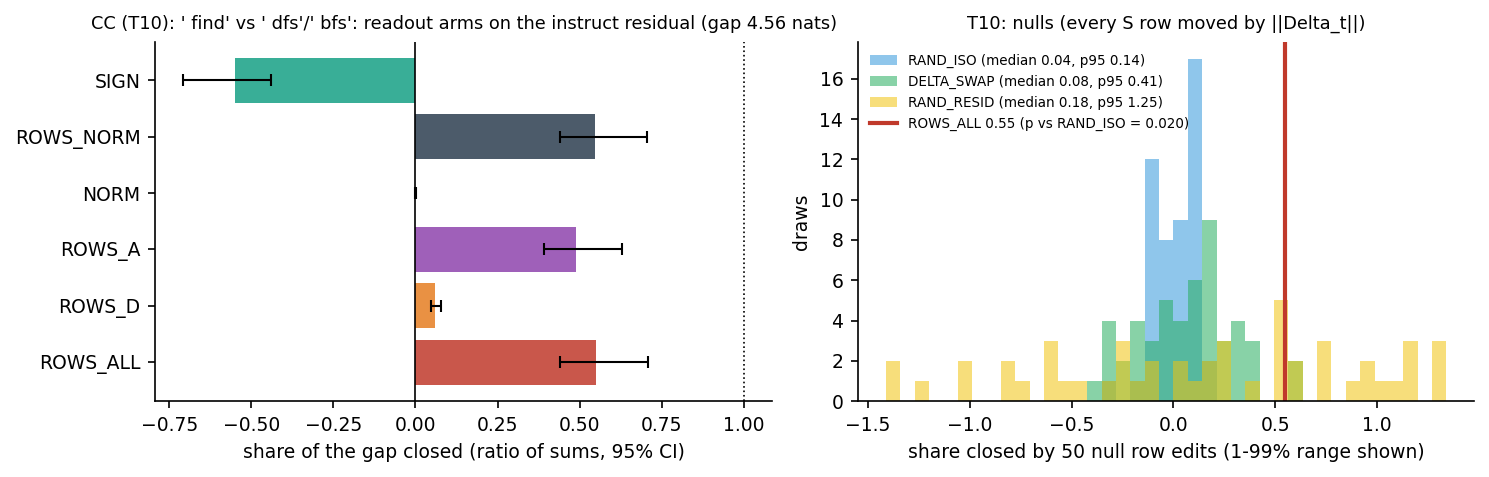

21:01:09|INFO   |shown F1_w1_shares_nulls


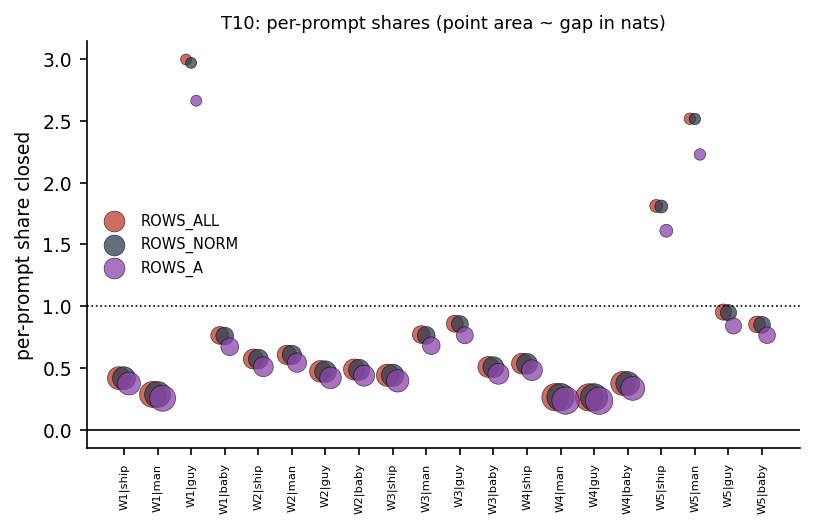

21:01:09|INFO   |shown F2_per_prompt_shares


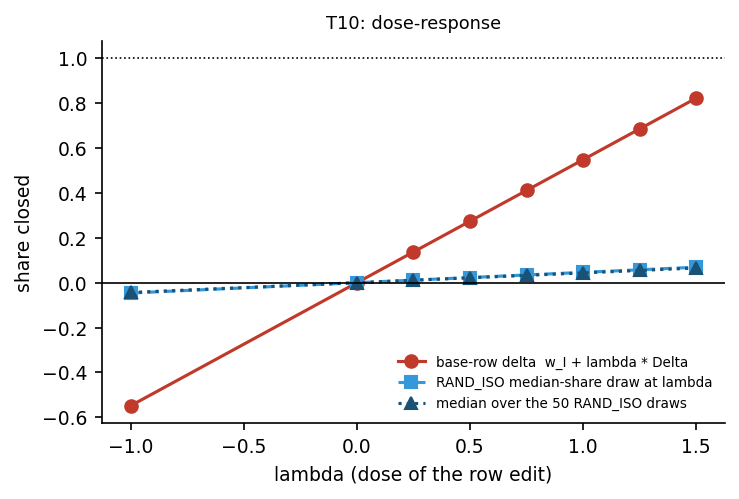

21:01:09|INFO   |shown F3_dose_response


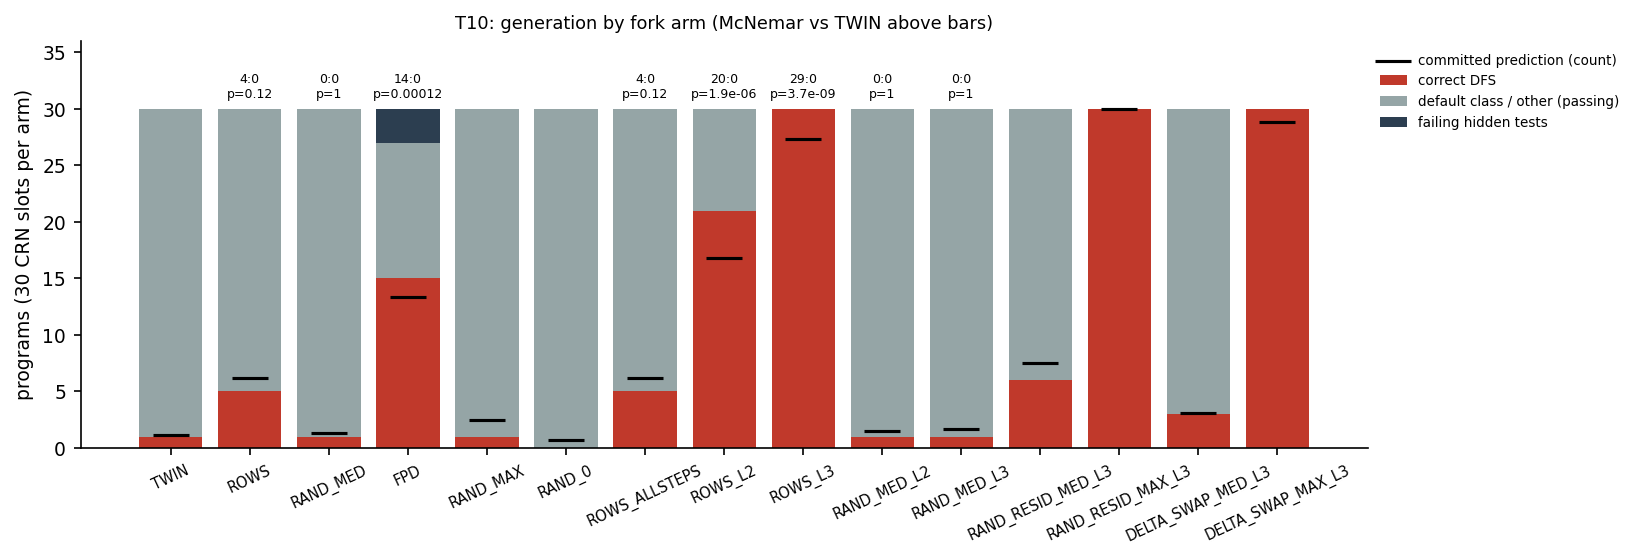

21:01:10|INFO   |shown F4_generation


In [17]:
plt.rcParams.update({"font.size": 9, "pdf.fonttype": 42, "ps.fonttype": 42, "axes.spines.top": False,
                     "axes.spines.right": False, "figure.dpi": 150})
C = {"ROWS_ALL": "#c0392b", "ROWS_D": "#e67e22", "ROWS_A": "#8e44ad", "NORM": "#7f8c8d", "ROWS_NORM": "#2c3e50",
     "SIGN": "#16a085", "RAND_ISO": "#3498db", "DELTA_SWAP": "#27ae60", "RAND_RESID": "#f1c40f", "instr": "#c0392b",
     "base": "#2980b9"}
NAMES = {"T10": "CC (T10): ' find' vs ' dfs'/' bfs'", "B3": "MST (B3): Kruskal vs Prim class"}


def save(fig: plt.Figure, name: str) -> None:
    fig.tight_layout()
    display(fig)                                 # demo: shown inline (was fig.savefig(FIG_DIR / f"{name}.pdf"/".png"))
    plt.close(fig)
    logger.info(f"shown {name}")


def f1(w1: dict) -> None:
    fig, axes = plt.subplots(len(UNITS_TF), 2, figsize=(10, 3.25 * len(UNITS_TF)), squeeze=False)  # demo: was (2, 2)
    arms = ["ROWS_ALL", "ROWS_D", "ROWS_A", "NORM", "ROWS_NORM", "SIGN"]
    for r, u in enumerate(UNITS_TF):
        U = w1["units"][u]
        ax = axes[r, 0]
        sh = [U["arms"][a]["share"] for a in arms]
        ci = [U["arms"][a]["ci95"] for a in arms]
        y = np.arange(len(arms))
        ax.barh(y, sh, color=[C[a] for a in arms], alpha=0.85)
        ax.errorbar(sh, y, xerr=[[s - c[0] for s, c in zip(sh, ci)], [c[1] - s for s, c in zip(sh, ci)]], fmt="none",
                    ecolor="k", capsize=3, lw=1)
        ax.set_yticks(y, arms)
        ax.axvline(0, color="k", lw=0.8)
        ax.axvline(1, color="k", lw=0.8, ls=":")
        ax.set_xlabel("share of the gap closed (ratio of sums, 95% CI)")
        ax.set_title(f"{NAMES[u]}: readout arms on the instruct residual (gap {U['gap_mean']:.2f} nats)", fontsize=8.5)
        ax = axes[r, 1]
        allv = np.concatenate([U["nulls"][nt]["shares"] for nt in ("RAND_ISO", "DELTA_SWAP", "RAND_RESID")])
        lo, hi = np.percentile(allv, 1), np.percentile(allv, 99)
        lo, hi = min(lo, -0.3), max(hi, U["arms"]["ROWS_ALL"]["share"] + 0.2)
        bins = np.linspace(lo, hi, 40)
        for nt in ("RAND_ISO", "DELTA_SWAP", "RAND_RESID"):
            v = np.clip(U["nulls"][nt]["shares"], lo, hi)
            ax.hist(v, bins=bins, alpha=0.55, color=C[nt],
                    label=f"{nt} (median {U['nulls'][nt]['median']:.2f}, p95 {U['nulls'][nt]['p95']:.2f})")
        ax.axvline(U["arms"]["ROWS_ALL"]["share"], color=C["ROWS_ALL"], lw=2,
                   label=f"ROWS_ALL {U['arms']['ROWS_ALL']['share']:.2f} (p vs RAND_ISO = "
                         f"{U['nulls']['RAND_ISO']['empirical_p_rows_all']:.3f})")
        ax.set_xlabel(f"share closed by {N_NULL} null row edits (1-99% range shown)")
        ax.set_ylabel("draws")
        ax.legend(fontsize=6.5, frameon=False)
        ax.set_title(f"{u}: nulls (every S row moved by ||Delta_t||)", fontsize=8.5)
    save(fig, "F1_w1_shares_nulls")


def f2(w1: dict) -> None:
    fig, axes = plt.subplots(1, len(UNITS_TF), figsize=(5.5 * len(UNITS_TF), 3.6), squeeze=False)  # demo: was (1, 2)
    for ax, u in zip(axes[0], UNITS_TF):
        U = w1["units"][u]
        gap = np.array(U["gap"])
        x = np.arange(len(gap))
        for a, off in (("ROWS_ALL", -0.15), ("ROWS_NORM", 0.0), ("ROWS_A", 0.15)):
            ax.scatter(x + off, U["arms"][a]["per_prompt_share"], s=12 + 18 * np.abs(gap), color=C[a], alpha=0.75,
                       label=a, edgecolor="k", lw=0.3)
        for i in np.nonzero(np.abs(gap) < 0.5)[0]:
            ax.annotate("gap<0.5", (i, U["arms"]["ROWS_ALL"]["per_prompt_share"][i]), fontsize=6)
        ax.axhline(0, color="k", lw=0.8)
        ax.axhline(1, color="k", lw=0.8, ls=":")
        ax.set_xticks(x, U["pids"], rotation=90, fontsize=5.5)
        ax.set_ylabel("per-prompt share closed")
        ax.set_title(f"{u}: per-prompt shares (point area ~ gap in nats)", fontsize=8.5)
        ax.legend(fontsize=7, frameon=False)
    save(fig, "F2_per_prompt_shares")


def f3(w1: dict) -> None:
    fig, axes = plt.subplots(1, len(UNITS_TF), figsize=(5 * len(UNITS_TF), 3.4), squeeze=False)    # demo: was (1, 2)
    for ax, u in zip(axes[0], UNITS_TF):
        U = w1["units"][u]
        lams = [-1.0, 0.0, 0.25, 0.5, 0.75, 1.0, 1.25, 1.5]
        rows = [U["arms"]["SIGN"]["share"], 0.0] + [U["arms"][f"DOSE_{l:g}"]["share"] for l in lams[2:]]
        cur = U["nulls"]["RAND_ISO"]["dose_curve"]
        iso_med = [cur["-1"]["median_draw_share"], 0.0] + [cur[f"{l:g}"]["median_draw_share"] for l in lams[2:]]
        iso_all = [cur["-1"]["all_draws_median_share"], 0.0] + [cur[f"{l:g}"]["all_draws_median_share"]
                                                                for l in lams[2:]]
        ax.plot(lams, rows, "o-", color=C["ROWS_ALL"], label="base-row delta  w_I + lambda * Delta")
        ax.plot(lams, iso_med, "s--", color=C["RAND_ISO"], label="RAND_ISO median-share draw at lambda")
        ax.plot(lams, iso_all, "^:", color="#1a5276", label=f"median over the {N_NULL} RAND_ISO draws")
        ax.axhline(0, color="k", lw=0.8)
        ax.axhline(1, color="k", lw=0.8, ls=":")
        ax.set_xlabel("lambda (dose of the row edit)")
        ax.set_ylabel("share closed")
        ax.set_title(f"{u}: dose-response", fontsize=8.5)
        ax.legend(fontsize=6.5, frameon=False)
    save(fig, "F3_dose_response")


def f4(gen: dict) -> None:
    us = [u for u in ("T10", "B3") if u in gen["units"]]                               # demo: the units present
    fig, axes = plt.subplots(len(us), 1, figsize=(11, 3.8 * len(us)), squeeze=False)  # demo: was (2, 1)
    for ax, u in zip(axes[:, 0], us):
        G = gen["units"][u]
        arms = list(G["cells"])
        corr_lab = {"T10": "correct DFS", "B3": "correct Prim"}[u]
        corr = np.array([G["cells"][a]["n_correct"] for a in arms])
        n = np.array([G["cells"][a]["n"] for a in arms])
        fails = np.array([G["cells"][a]["n"] - G["cells"][a]["n_pass"] for a in arms])
        other = n - corr - fails
        x = np.arange(len(arms))
        ax.bar(x, corr, color="#c0392b", label=corr_lab)
        ax.bar(x, other, bottom=corr, color="#95a5a6", label="default class / other (passing)")
        ax.bar(x, fails, bottom=corr + other, color="#2c3e50", label="failing hidden tests")
        pred = [G["cells"][a]["predicted_correct_count"] * G["cells"][a]["n"] / 30 for a in arms]   # demo: per n slots
        ax.scatter(x, pred, marker="_", s=300, color="k", zorder=5, label="committed prediction (count)")
        for i, a in enumerate(arms):
            t = G["tests"].get(f"{a}_vs_TWIN")
            if t and a != "TWIN":
                ax.annotate(f"{t['b_first_only']}:{t['c_second_only']}\np={t['p_exact_two_sided']:.2g}",
                            (i, max(n) + 1), ha="center", fontsize=6)
        ax.set_xticks(x, arms, rotation=25, fontsize=7)
        ax.set_ylim(0, max(n) * 1.2)                                           # demo: was 36 (= 30 slots + labels)
        ax.set_ylabel(f"programs ({max(n)} CRN slots per arm)")
        ax.set_title(f"{u}: generation by fork arm (McNemar vs TWIN above bars)", fontsize=8.5)
        ax.legend(fontsize=6.5, frameon=False, loc="upper left", bbox_to_anchor=(1.0, 1.0))
    save(fig, "F4_generation")


f1(w1)
f2(w1)
f3(w1)
f4(gen)


## Activation space: where the fork states live (`figures10.f5_f6`)

These two plots show actual activation coordinates, not summary statistics.

**F5, the readout plane.** Take the instruct readout direction $u_1 \propto \bar w_{I,D}-\bar w_{I,A}$ (mean default row
minus mean alternative row), and the base readout direction $\bar w_{B,D}-\bar w_{B,A}$ orthogonalised against $u_1$
(that is $u_2$). Every final-normed fork state $h_\text{fin}$ (20 instruct as circles, 20 base as squares) is projected
onto $(u_1, u_2)$. The isolines are the class margin over that plane, through the mean off-plane component. The solid
isolines use the instruct S rows; the dashed ones use the base S rows (the ROWS_ALL readout).

Restoring the base rows changes the margin field the same states sit in. The instruct states (red) fall on lower dashed
isolines than solid ones, which is the ROWS_ALL share. The base states (blue) also sit in a different region of the plane,
which is the residual part of the gap.

**F6, the block-35 outputs.** This is a PCA of the final-norm inputs $h_\text{pre}$ at the fork, for both models together.
The two readout directions are overlaid as arrows, with their |projection| onto the PC plane in the legend. PC1 (about 99%
of the variance) simply separates the two models: their block-35 outputs live far apart. Both readout directions are
nearly orthogonal to this plane (|projection| about 0.10). The margin is read along directions that carry almost none of
the residual's variance, which is why the class readout rows are such a small, cheap lever.


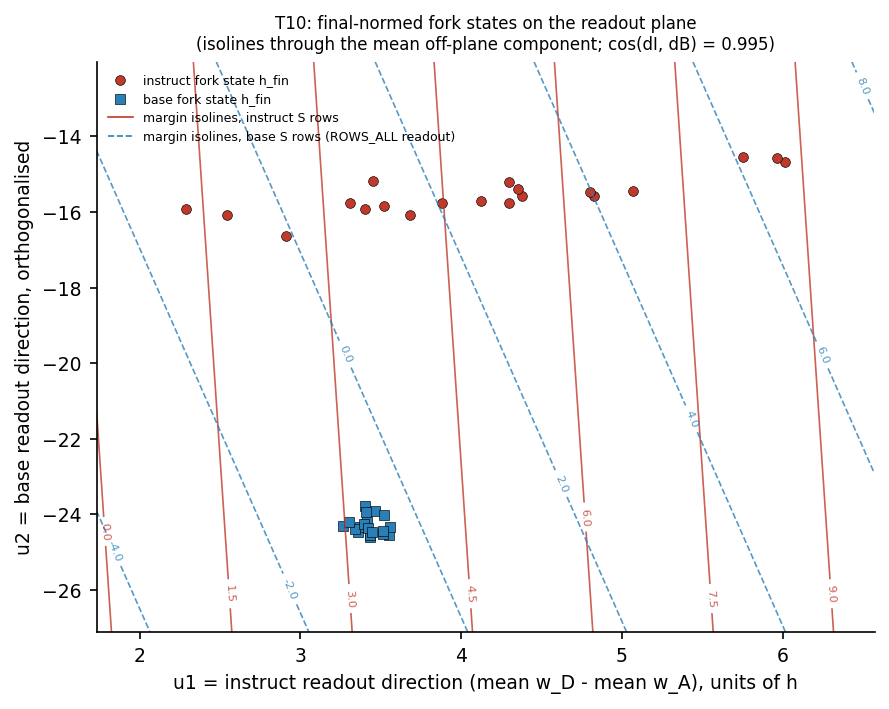

21:01:10|INFO   |shown F5_readout_plane


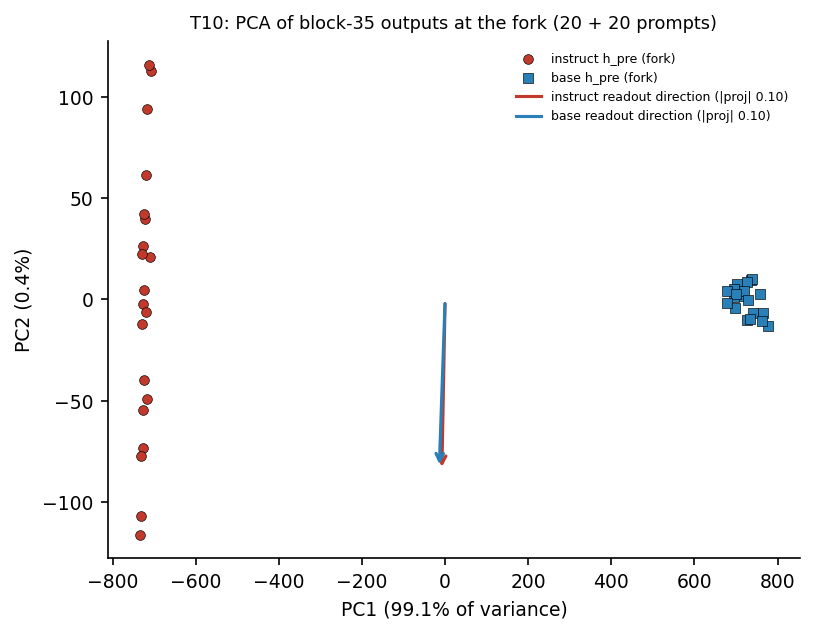

21:01:10|INFO   |shown F6_pca_block35


In [18]:
def f5_f6() -> None:
    # demo: UnitData / load_readout are defined above (was from w1_tf import ...); units comes from the adapter cell
    WI, gI = load_readout("qwen")
    WB, gB = load_readout("qwen_base")
    fig5, ax5 = plt.subplots(1, len(UNITS_TF), figsize=(6 * len(UNITS_TF), 4.8), squeeze=False)   # demo: was (1, 2)
    fig6, ax6 = plt.subplots(1, len(UNITS_TF), figsize=(5.5 * len(UNITS_TF), 4.3), squeeze=False)
    for k, u in enumerate(UNITS_TF):
        d = UnitData(u, units, WI, WB, gI, gB, need_logits=False)
        WI_S, WB_S = d.WI_S.double(), d.WB_S.double()
        dI = WI_S[:d.nD].mean(0) - WI_S[d.nD:].mean(0)
        dB = WB_S[:d.nD].mean(0) - WB_S[d.nD:].mean(0)
        u1 = dI / dI.norm()
        v = dB - (dB @ u1) * u1
        u2 = v / v.norm()
        H = torch.cat([d.hfI, d.hfB]).double()
        a, b = (H @ u1).numpy(), (H @ u2).numpy()
        off = H - torch.outer(H @ u1, u1) - torch.outer(H @ u2, u2)
        off_mean = off.mean(0)
        ga = np.linspace(a.min() - 0.15 * np.ptp(a), a.max() + 0.15 * np.ptp(a), 120)
        gb = np.linspace(b.min() - 0.25 * np.ptp(b), b.max() + 0.25 * np.ptp(b), 120)
        A_, B_ = np.meshgrid(ga, gb)
        G = (off_mean[None, None, :] + torch.from_numpy(A_)[..., None] * u1 + torch.from_numpy(B_)[..., None] * u2)
        G = G.reshape(-1, G.shape[-1])

        def mgrid(rows: torch.Tensor) -> np.ndarray:
            z = G @ rows.T
            return (torch.logsumexp(z[:, :d.nD], -1) - torch.logsumexp(z[:, d.nD:], -1)).numpy().reshape(A_.shape)
        MI, MB = mgrid(WI_S), mgrid(WB_S)
        ax = ax5[0, k]
        cs1 = ax.contour(A_, B_, MI, levels=7, colors=C["instr"], linewidths=0.8, alpha=0.8)
        ax.clabel(cs1, fontsize=5.5, fmt="%.1f")
        cs2 = ax.contour(A_, B_, MB, levels=7, colors=C["base"], linewidths=0.8, linestyles="--", alpha=0.8)
        ax.clabel(cs2, fontsize=5.5, fmt="%.1f")
        n = len(d.pids)
        ax.scatter(a[:n], b[:n], color=C["instr"], s=22, edgecolor="k", lw=0.3, label="instruct fork state h_fin")
        ax.scatter(a[n:], b[n:], color=C["base"], s=22, marker="s", edgecolor="k", lw=0.3,
                   label="base fork state h_fin")
        ax.plot([], [], color=C["instr"], lw=0.8, label="margin isolines, instruct S rows")
        ax.plot([], [], color=C["base"], lw=0.8, ls="--", label="margin isolines, base S rows (ROWS_ALL readout)")
        ax.set_xlabel("u1 = instruct readout direction (mean w_D - mean w_A), units of h")
        ax.set_ylabel("u2 = base readout direction, orthogonalised")
        ax.set_title(f"{u}: final-normed fork states on the readout plane\n(isolines through the mean off-plane "
                     f"component; cos(dI, dB) = {float(dI @ dB / dI.norm() / dB.norm()):.3f})", fontsize=8)
        ax.legend(fontsize=6, frameon=False, loc="best")
        # F6 PCA of block-35 outputs (final-norm inputs) at the fork
        P = torch.cat([d.hpI.float(), d.hpB.float()]).double()
        mu = P.mean(0)
        Uu, Ss, Vt = torch.linalg.svd(P - mu, full_matrices=False)
        pcs = Vt[:2]
        Y = ((P - mu) @ pcs.T).numpy()
        ev = (Ss ** 2 / (Ss ** 2).sum()).numpy()
        ax = ax6[0, k]
        ax.scatter(Y[:n, 0], Y[:n, 1], color=C["instr"], s=22, edgecolor="k", lw=0.3, label="instruct h_pre (fork)")
        ax.scatter(Y[n:, 0], Y[n:, 1], color=C["base"], s=22, marker="s", edgecolor="k", lw=0.3,
                   label="base h_pre (fork)")
        sc = 0.35 * np.abs(Y).max()
        for vec, col, lab in ((dI, C["instr"], "instruct readout direction"), (dB, C["base"], "base readout direction")):
            p2 = (pcs @ (vec / vec.norm())).numpy()
            ax.annotate("", xy=(sc * p2[0] / max(1e-9, np.linalg.norm(p2)) * min(1, 3 * np.linalg.norm(p2)),
                                sc * p2[1] / max(1e-9, np.linalg.norm(p2)) * min(1, 3 * np.linalg.norm(p2))),
                        xytext=(0, 0), arrowprops=dict(arrowstyle="->", color=col, lw=1.5))
            ax.plot([], [], color=col, label=f"{lab} (|proj| {np.linalg.norm(p2):.2f})")
        ax.set_xlabel(f"PC1 ({100 * ev[0]:.1f}% of variance)")
        ax.set_ylabel(f"PC2 ({100 * ev[1]:.1f}%)")
        ax.set_title(f"{u}: PCA of block-35 outputs at the fork ({n} + {n} prompts)", fontsize=8.5)
        ax.legend(fontsize=6, frameon=False)
    fig5.tight_layout()
    save(fig5, "F5_readout_plane")
    save(fig6, "F6_pca_block35")


f5_f6()


## Results: reproduced here vs reported by the full run

The table puts every headline T10 number recomputed in this notebook next to the value in the full run's `results/*.json`.
The reported values ship in the data file.

At the original scale (`N_PROMPTS = 20`, `N_NULL = 50`, `N_BOOT = 10000`), the arithmetic is the same and the inputs are
bit-identical, so the two columns agree to float precision. At a reduced scale they differ by design, because fewer
prompts, draws and resamples are used.

The figure shows two panels:
* left: reproduced vs reported values (all on the diagonal at full scale);
* right: the generation lever, i.e. how many programs per arm implement the **alternative** algorithm (DFS) correctly.

The numbers that need the 8B models on a GPU follow at the end (unit B3, W2 late-MLP swaps, W3 Gemma); they are
reported, not recomputed.


scale: N_PROMPTS=20, N_NULL=50, N_BOOT=10000 (the original scale)

         quantity                                                        here    reported     |diff|
S0       gap mean m_I - m_B (nats)                                      4.558       4.558   0.00e+00
S0       unembedding-only share (target 0.85)                          0.8418      0.8418   0.00e+00
S0       G1 bit-exact prompts                                              20          20   0.00e+00
W1-TF    share ROWS_ALL                                                0.5485      0.5485   0.00e+00
W1-TF    share ROWS_D                                                 0.05953     0.05953   0.00e+00
W1-TF    share ROWS_A                                                  0.4889      0.4889   0.00e+00
W1-TF    share NORM                                                -0.0002993  -0.0002993   0.00e+00
W1-TF    share ROWS_NORM                                               0.5468      0.5468   0.00e+00
W1-TF    share FULL_UNEM

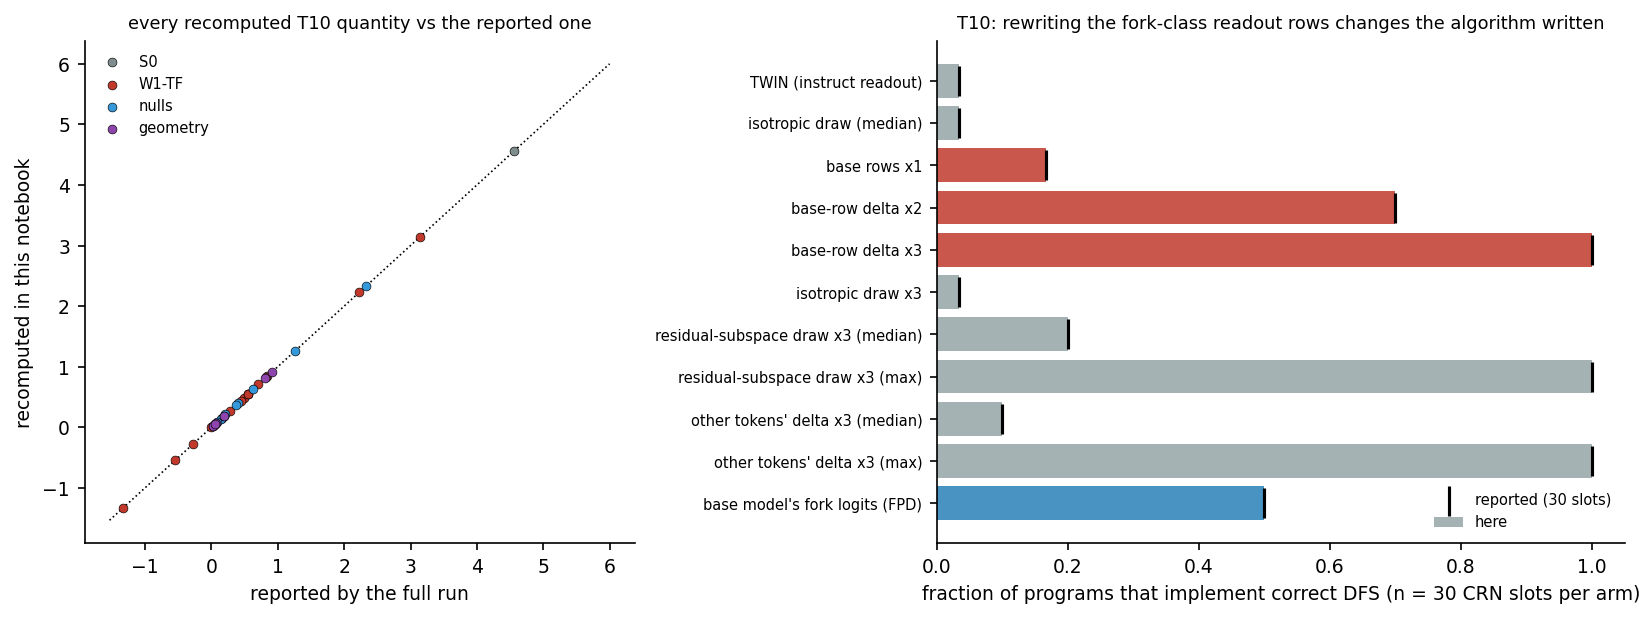


Reported only (need the 8B models on a GPU, or unit B3's data):
  W1-TF B3 (MST, beside): ROWS_ALL 1.249 [1.18, 1.323], ROWS_A 1.240, ROWS_D 0.009; RAND_ISO median 0.051, RAND_RESID p95 5.39; interaction +1.748 nats
  W1-GEN B3 correct Prim of 30: TWIN 0, ROWS 24, ROWS_L3 27, RAND_MED_L3 3, RAND_RESID_MED_L3 28
  W2 T10: late MLPs 26-35 -> base -0.145 vs matched early swaps 0.461 (diff -0.606 [-0.78, -0.48]); same-layer random deltas [-0.36, 0.21, -0.29] -> rule holds: False
  W2 B3: late MLPs 26-35 -> base 0.313 vs matched early swaps 0.317 (diff -0.004 [-0.06, 0.05]); same-layer random deltas [0.59, -0.54, -0.01] -> rule holds: False
  W3 Gemma-3-4b grid fork: gap 1.83 nats; ROWS_ALL -0.253, ROWS_D 0.376, ROWS_A -0.629, SIGN 1.429
  audit: 425 stdlib checks, 0 mismatches; float64 headline re-derivation within 4.4e-07; LeetCode 323/547 dependency check 627/630 programs pass


In [19]:
ref = U_DATA["T10"]["reference"]
RW, RS0, RG, RP, RGEO = (ref["w1_tf"], ref["stage0"], ref["w1_generation"], ref["w1_generation_power"],
                         ref["delta_geometry"])
W, r0, G, P = w1["units"]["T10"], s0["units"]["T10"], gen["units"]["T10"], power["units"]["T10"]
geo_t = geo["units"]["T10"]["tokens"]
FULL_SCALE = (N_PROMPTS, N_NULL, N_BOOT) == (20, 50, 10000)

rows = []   # (section, quantity, reproduced here, reported by the full run)
rows.append(("S0", "gap mean m_I - m_B (nats)", W["gap_mean"], RW["gap_mean"]))
rows.append(("S0", "unembedding-only share (target 0.85)",
             r0["readout_decomposition_cpu"]["share_unembedding_only"],
             RS0["readout_decomposition_cpu"]["share_unembedding_only"]))
rows.append(("S0", "G1 bit-exact prompts", r0["G1"]["bit_exact_prompts"], RS0["G1"]["bit_exact_prompts"]))
for a in ("ROWS_ALL", "ROWS_D", "ROWS_A", "NORM", "ROWS_NORM", "FULL_UNEMB", "SIGN", "DOSE_0.5", "DOSE_1.5",
          "UNEMB_ONLY_on_base_resid"):
    rows.append(("W1-TF", f"share {a}", W["arms"][a]["share"], RW["arms"][a]["share"]))
rows.append(("W1-TF", "ROWS_ALL 95% CI, low", W["arms"]["ROWS_ALL"]["ci95"][0], RW["arms"]["ROWS_ALL"]["ci95"][0]))
rows.append(("W1-TF", "ROWS_ALL 95% CI, high", W["arms"]["ROWS_ALL"]["ci95"][1], RW["arms"]["ROWS_ALL"]["ci95"][1]))
for nt in NULL_TYPES:
    for k in ("median", "p95", "max", "empirical_p_rows_all"):
        rows.append(("nulls", f"{nt} {k}", W["nulls"][nt][k], RW["nulls"][nt][k]))
rows.append(("W1-TF", "2x2 interaction (nats)", W["factorial_2x2"]["interaction_mean"],
             RW["factorial_2x2"]["interaction_mean"]))
for t in W["per_token_logit_change"]:
    rows.append(("W1-TF", f"fork-logit change of {t!r} (nats)", W["per_token_logit_change"][t]["mean"],
                 RW["per_token_logit_change"][t]["mean"]))
for t, v in geo_t.items():
    rows.append(("geometry", f"{TOK.decode([int(t)])!r}: Delta energy in residual PC64",
                 v["frac_delta_energy_in_resid_pc64"], RGEO["tokens"][t]["frac_delta_energy_in_resid_pc64"]))
    rows.append(("geometry", f"{TOK.decode([int(t)])!r}: leverage real / RAND_RESID median",
                 v["leverage_real_mean"] / v["leverage_rand_resid_median"],
                 RGEO["tokens"][t]["leverage_real_mean"] / RGEO["tokens"][t]["leverage_rand_resid_median"]))
gen_arms = ("TWIN", "RAND_MED", "ROWS", "ROWS_L2", "ROWS_L3", "RAND_MED_L3", "RAND_RESID_MED_L3", "RAND_RESID_MAX_L3",
            "DELTA_SWAP_MED_L3", "DELTA_SWAP_MAX_L3", "FPD")
for a in gen_arms:
    rows.append(("W1-GEN", f"correct DFS, {a} (of {G['cells'][a]['n']} here / 30)", G["cells"][a]["n_correct"],
                 RG["cells"][a]["n_correct"]))
for k in ("ROWS_vs_TWIN", "ROWS_L3_vs_TWIN"):
    rows.append(("W1-GEN", f"McNemar {k} p", G["tests"][k]["p_exact_two_sided"], RG["tests"][k]["p_exact_two_sided"]))
for a in POWER_ARMS:
    rows.append(("W1-GEN", f"pooled correct DFS, {a} (of {P['cells'][a]['n']} here / 90)", P["cells"][a]["n_correct"],
                 RP["cells"][a]["n_correct"]))
rows.append(("W1-GEN", "pooled McNemar ROWS vs TWIN p", P["tests"]["ROWS_vs_TWIN"]["p_exact_two_sided"],
             RP["tests"]["ROWS_vs_TWIN"]["p_exact_two_sided"]))

print(f"scale: N_PROMPTS={N_PROMPTS}, N_NULL={N_NULL}, N_BOOT={N_BOOT} "
      f"({'the original scale' if FULL_SCALE else 'REDUCED: values differ from the full run by design'})\n")
print(f"{'':<9}{'quantity':<56}{'here':>12}{'reported':>12}{'|diff|':>11}")
diffs = []
for sec, q, mine, rep in rows:
    dd = abs(float(mine) - float(rep))
    diffs.append(dd)
    print(f"{sec:<9}{q:<56}{mine:>12.4g}{rep:>12.4g}{dd:>11.2e}")
print(f"\nmax |here - reported| over {len(rows)} numbers: {max(diffs):.2e}")
for name, mine, rep in (("W1-TF verdict (T10)", W["verdict"], RW["verdict"]),
                        ("W1-TF qualifier", W["specificity_qualifier"], RW["specificity_qualifier"]),
                        ("W1-GEN verdict (T10)", G["verdict"], RG["verdict"])):
    print(f"{name:<22} here: {mine:<40} reported: {rep}")

# ---- figure: agreement (left) and the generation lever (right)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), gridspec_kw={"width_ratios": [1, 1.25]})
ax = axes[0]
cols = {"S0": "#7f8c8d", "W1-TF": "#c0392b", "nulls": "#3498db", "geometry": "#8e44ad"}
for sec, col in cols.items():
    pts = [(float(rep), float(mine)) for s, q, mine, rep in rows if s == sec and abs(float(rep)) < 10]
    if pts:
        ax.scatter(*zip(*pts), s=18, color=col, edgecolor="k", lw=0.3, label=sec, zorder=3)
lim = [min(-1.0, min(float(r[3]) for r in rows if abs(float(r[3])) < 10) - 0.2), 6.0]
ax.plot(lim, lim, color="k", lw=0.8, ls=":", zorder=1)
ax.set_xlabel("reported by the full run")
ax.set_ylabel("recomputed in this notebook")
ax.set_title("every recomputed T10 quantity vs the reported one", fontsize=8.5)
ax.legend(fontsize=7, frameon=False)
ax = axes[1]
lab = {"TWIN": "TWIN (instruct readout)", "RAND_MED": "isotropic draw (median)", "ROWS": "base rows x1",
       "ROWS_L2": "base-row delta x2", "ROWS_L3": "base-row delta x3", "RAND_MED_L3": "isotropic draw x3",
       "RAND_RESID_MED_L3": "residual-subspace draw x3 (median)", "RAND_RESID_MAX_L3": "residual-subspace draw x3 (max)",
       "DELTA_SWAP_MED_L3": "other tokens' delta x3 (median)", "DELTA_SWAP_MAX_L3": "other tokens' delta x3 (max)",
       "FPD": "base model's fork logits (FPD)"}
y = np.arange(len(gen_arms))[::-1]
here = [G["cells"][a]["n_correct"] / G["cells"][a]["n"] for a in gen_arms]
rep = [RG["cells"][a]["n_correct"] / RG["cells"][a]["n"] for a in gen_arms]
ax.barh(y, here, color=["#c0392b" if a.startswith("ROWS") else "#95a5a6" if a != "FPD" else "#2980b9"
                        for a in gen_arms], alpha=0.85, label="here")
ax.scatter(rep, y, marker="|", s=200, color="k", zorder=4, label="reported (30 slots)")
ax.set_yticks(y, [lab[a] for a in gen_arms], fontsize=7)
ax.set_xlim(0, 1.05)
ax.set_xlabel(f"fraction of programs that implement correct DFS (n = {G['cells']['TWIN']['n']} CRN slots per arm)")
ax.set_title("T10: rewriting the fork-class readout rows changes the algorithm written", fontsize=8.5)
ax.legend(fontsize=7, frameon=False, loc="lower right")
fig.tight_layout()
display(fig)
plt.close(fig)

# ---- what this notebook cannot recompute: reported numbers of the GPU stages
ctx = data["reported_context"]
b3 = ctx["W1_TF_B3"]
print("\nReported only (need the 8B models on a GPU, or unit B3's data):")
print(f"  W1-TF B3 (MST, beside): ROWS_ALL {b3['shares']['ROWS_ALL']:.3f} {np.round(b3['ROWS_ALL_ci95'], 3).tolist()}, "
      f"ROWS_A {b3['shares']['ROWS_A']:.3f}, ROWS_D {b3['shares']['ROWS_D']:.3f}; RAND_ISO median "
      f"{b3['nulls']['RAND_ISO']['median']:.3f}, RAND_RESID p95 {b3['nulls']['RAND_RESID']['p95']:.2f}; "
      f"interaction {b3['interaction_mean']:+.3f} nats")
print(f"  W1-GEN B3 correct Prim of 30: " + ", ".join(f"{a} {ctx['W1_GEN_B3_correct_of_30'][a]}" for a in
                                                      ("TWIN", "ROWS", "ROWS_L3", "RAND_MED_L3", "RAND_RESID_MED_L3")))
for u in ("T10", "B3"):
    rr = ctx["W2"][u]["rule"]
    print(f"  W2 {u}: late MLPs 26-35 -> base {rr['late_joint']:.3f} vs matched early swaps {rr['early_joint']:.3f} "
          f"(diff {rr['diff']:.3f} {np.round(rr['diff_ci95'], 2).tolist()}); same-layer random deltas "
          f"{np.round(rr['randdelta_joint_shares'], 2).tolist()} -> rule holds: {rr['holds']}")
w3 = ctx["W3_G-GRID"]
print(f"  W3 Gemma-3-4b grid fork: gap {w3['gap']:.2f} nats; ROWS_ALL {w3['shares']['ROWS_ALL']:.3f}, ROWS_D "
      f"{w3['shares']['ROWS_D']:.3f}, ROWS_A {w3['shares']['ROWS_A']:.3f}, SIGN {w3['shares']['SIGN']:.3f}")
print(f"  audit: {ctx['audit']['n_checks']} stdlib checks, {ctx['audit']['n_mismatches']} mismatches; float64 headline "
      f"re-derivation within {ctx['headline_rederivation_max_abs_diff']:.1e}; LeetCode 323/547 dependency check "
      f"{ctx['dependency_check']['n_dep_pass']}/{ctx['dependency_check']['n_programs']} programs pass")


## What this means for "can we make the model pick a different, less default solution?"

* **Where the default sits at the decision token.** In Qwen3-8B on CC, post-training wrote much of the default as a
  **readout** change. Restoring the base fork-class rows, 3 of 151,936, closes about **0.55** of the instruct-minus-base
  gap. The committed rule calls this SUPPORTED against isotropic matched-norm edits (p = 1/51).
* **How post-training wrote it.** Mostly by **suppressing the alternatives' rows**. The base rows raise ` dfs` by about
  +2.2 and ` bfs` by about +3.1 nats, while ` find` moves by −0.27. ROWS_A alone closes 0.49 of the gap; ROWS_D closes
  0.06. The final-norm gain contributes nothing.
* **It is a lever, but not a unique one.** The qualifier reads "readout-level, not token-specific". Equal-norm random
  edits aimed at the residual's top-64 subspace reach the same shares (p = 0.37). The delta geometry explains this: the
  ` dfs` / ` bfs` deltas point into the residual subspace, but only partly, and the ` find` delta is isotropic.
* **In generation**, the row edit changes **which known algorithm gets written**:
  * at ×1, 21/90 correct DFS against 4/90 for TWIN, 17:0 on CRN pairs;
  * at ×3, 30/30, with every program still passing the hidden tests;
  * but the best residual-subspace and delta-transplant draws at ×3 do just as well.
* **What it does not do.** No edit produced a correct program outside the known classes. The lever redistributes mass
  among the existing algorithms; it does not create novelty.
* **The other two arms** (reported above, not recomputed here). The late MLPs (W2) are not where the default is held in
  any specific way. In Gemma-3-4b (W3), the base rows *widen* the gap, so the readout story depends on the model family.

**To reproduce the full run:** set `N_PROMPTS = 20`, `N_NULL = 50`, `N_BOOT = 10000` in the configuration cell. These are
the defaults this notebook ships with; at that scale every number above matches the reported one to float precision. The
GPU stages (captures, generation, W2, W3) need `method.py` from the original artifact with the pinned 8B checkpoints.
